# Neanderthal Ancestry and Cancer Risk — Figures

This notebook contains the code necessary to produce the figures for the
Neanderthal Ancestry and Cancer Risk project. Sections follow the order of
appearance in the manuscript, and their numbers match the companion
`analysis.ipynb`; sections with no figure are skipped, so the numbering has
gaps. Use the Contents below to navigate.

Figures are drawn from the pipeline outputs on Wynton and from tables written
by `analysis.ipynb`, so run that notebook first. Each section names the PDF it
writes. Main-figure components go to `figures/main_fig_components/` and
supplementary figures to `figures/suppl_figs/`; panels marked as placeholders
are completed outside R.

## Contents

- [1. Setup](#1.-Setup)
- [3. Neanderthal variant maps](#3.-Neanderthal-variant-maps)
- [4. Neanderthal variant MAFs](#4.-Neanderthal-variant-MAFs)
- [5. GWAS loci with Neanderthal variants](#5.-GWAS-loci-with-Neanderthal-variants)
- [7. Neanderthal-majority signals](#7.-Neanderthal-majority-signals)
- [9. Locus examples](#9.-Locus-examples)
- [10. Ancient DNA](#10.-Ancient-DNA)
- [11. Heritability](#11.-Heritability)
- [13. Session information](#13.-Session-information)

## 1. Setup

Libraries, paths, the shared figure theme and colours, and helpers used by
more than one figure. Paths mirror the directory variables in
`analysis.ipynb`.

In [1]:
library(cowplot)
library(ComplexUpset)
library(data.table)
library(dplyr)
library(eulerr)
library(ggExtra)
library(ggplot2)
library(ggpubr)
library(ggrepel)
library(ggtext)
library(grid)
library(gridExtra)
library(gtable)
library(patchwork)
library(readr)
library(scales)
library(stringr)
library(tidyr)

options(scipen = 999)
pdfFonts(Arial = pdfFonts()$Helvetica)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘ggpubr’


The following object is masked from ‘package:cowplot’:

    get_legend



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine



Attaching package: ‘patchwork’


The following object is masked from ‘package:cowplot’:

    align_plots



Attaching package: ‘scales’


The following object is masked from ‘package:readr’:

    col_factor




In [2]:
project_directory <-
  "/wynton/group/capra/projects/neanderthal_ancestry_and_cancer_risk"
stopifnot(dir.exists(project_directory))

# The sourced locuszoom and PIP helpers may read inputs by relative path, so
# the working directory stays at the project root. Everything in this notebook
# uses the absolute paths below.
setwd(project_directory)

data_directory <- file.path(project_directory, "data")
ancient_genomes_directory <- file.path(data_directory, "ancient_genomes")
fine_mapping_directory <- file.path(data_directory, "fine_mapping")
gwas_summary_stats_directory <- file.path(data_directory, "GWAS_summary_stats")
introgressed_variants_directory <-
  file.path(data_directory, "introgressed_variants")
ldsc_directory <-
  file.path(data_directory, "LD_score_regression", "results", "summaries")
open_targets_directory <- file.path(data_directory, "Open_Targets")
supplementary_tables_directory <-
  file.path(data_directory, "supplementary_tables")
notebooks_directory <- file.path(project_directory, "scripts", "notebooks")

figures_directory <- file.path(project_directory, "figures")
main_figures_directory <- file.path(figures_directory, "main_fig_components")
supplementary_figures_directory <- file.path(figures_directory, "suppl_figs")

In [3]:
save_pdf <- function(plot, path, width, height) {
  cairo_pdf(filename = path, width = width, height = height)
  print(plot)
  dev.off()
}

save_png <- function(plot, path, width, height, res = 600) {
  png(
    filename = path,
    width = width,
    height = height,
    units = "in",
    res = res,
    type = "cairo"
  )
  print(plot)
  dev.off()
}

# The fine-mapping pipeline writes `<name>_current.<ext>` beside the stable
# file after a partial rerun; prefer it, as analysis.ipynb does.
prefer_current <- function(path) {
  current <- sub("(\\.[^.]+)$", "_current\\1", path)
  if (file.exists(current)) current else path
}

fine_mapping_result_file <- function(gwas, locus_id, ancestry_group) {
  file.path(
    fine_mapping_directory, "results", gwas,
    paste0(locus_id, "_", ancestry_group, ".rds")
  )
}

In [4]:
cancer_name_mappings <- c(
  "basal_cell_carcinoma" = "BCC",
  "bladder_cancer" = "Bladder",
  "breast_cancer" = "Breast",
  "colorectal_cancer" = "Colorectal",
  "endometrial_cancer" = "Endometrial",
  "esophageal_cancer" = "Esophageal",
  "gastric_cancer" = "Gastric",
  "liver_cancer" = "Liver",
  "lung_cancer" = "Lung",
  "melanoma" = "Melanoma",
  "ovarian_cancer" = "Ovarian",
  "pancreatic_cancer" = "Pancreatic",
  "prostate_cancer" = "Prostate",
  "renal_cancer" = "Renal",
  "squamous_cell_carcinoma" = "SCC",
  "testicular_cancer" = "Testicular",
  "thyroid_cancer" = "Thyroid"
)

# Short cancer label from a pipeline key such as
# "basal_cell_carcinoma_EUR_Seviiri_GCST90137411" or "basal_cell_carcinoma".
short_cancer <- function(key) {
  prefix <- str_remove(key, "_(EUR|EAS)_.*$")
  unname(coalesce(
    cancer_name_mappings[prefix],
    str_to_title(str_replace_all(prefix, "_", " "))
  ))
}

In [5]:
hairline <- 0.125 / 0.377

primary_colour <- "#007C83"
raa_colour <- "#C9601E"
r2_colours <- c("0.2" = "#9BC9CB", "0.5" = "#007C83", "0.8" = "#07565A")

fig_theme <- theme_classic() +
  theme(
    text = element_text(family = "Arial"),
    axis.line.x.bottom = element_line(linewidth = hairline),
    axis.line.y.left = element_line(linewidth = hairline),
    axis.ticks = element_line(linewidth = hairline),
    axis.title = element_text(size = 12),
    axis.title.x = element_text(margin = margin(t = 20)),
    axis.title.y = element_text(margin = margin(r = 20)),
    axis.text = element_text(size = 11)
  )

# plot_grid with the panel-label style used in every figure
plot_grid_labelled <- function(..., labels, label_size = 24) {
  plot_grid(
    ...,
    labels = labels,
    label_fontface = "plain",
    label_size = label_size
  )
}

# The locuszoom-over-PIPs layout shared by the locus example figures
stack_locuszoom_and_pips <- function(locuszoom_plot, pips_plot) {
  plot_grid_labelled(
    locuszoom_plot,
    pips_plot,
    labels = c("A", "B"),
    ncol = 1,
    align = "v",
    axis = "lr",
    rel_heights = c(0.7, 0.3),
    scale = 0.9
  )
}

## 3. Neanderthal variant maps

Upset plot of the four Neanderthal variant maps, from the membership table
written by `analysis.ipynb`. Output: `suppl_figs/neanderthal_variant_maps_upset.pdf`.

In [6]:
neanderthal_maps <- c("Browning", "Sankararaman", "Skov", "Vernot")

neanderthal_map_memberships <- read_tsv(
  file.path(
    introgressed_variants_directory,
    "neanderthal_variant_map_memberships.txt"
  ),
  show_col_types = FALSE
) %>%
  as.data.frame()

head(neanderthal_map_memberships)

,chr_pos,Browning,Sankararaman,Skov,Vernot
,<chr>,<lgl>,<lgl>,<lgl>,<lgl>
1,10_100012192,FALSE,FALSE,TRUE,FALSE
2,10_100012395,FALSE,FALSE,TRUE,TRUE
3,10_100012583,FALSE,FALSE,TRUE,TRUE
4,10_100012836,FALSE,FALSE,FALSE,TRUE
5,10_100015098,FALSE,FALSE,TRUE,FALSE
6,10_100015722,FALSE,FALSE,TRUE,FALSE


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ComplexUpset package.
  Please report the issue at <https://github.com/krassowski/complex-upset/issues>.”


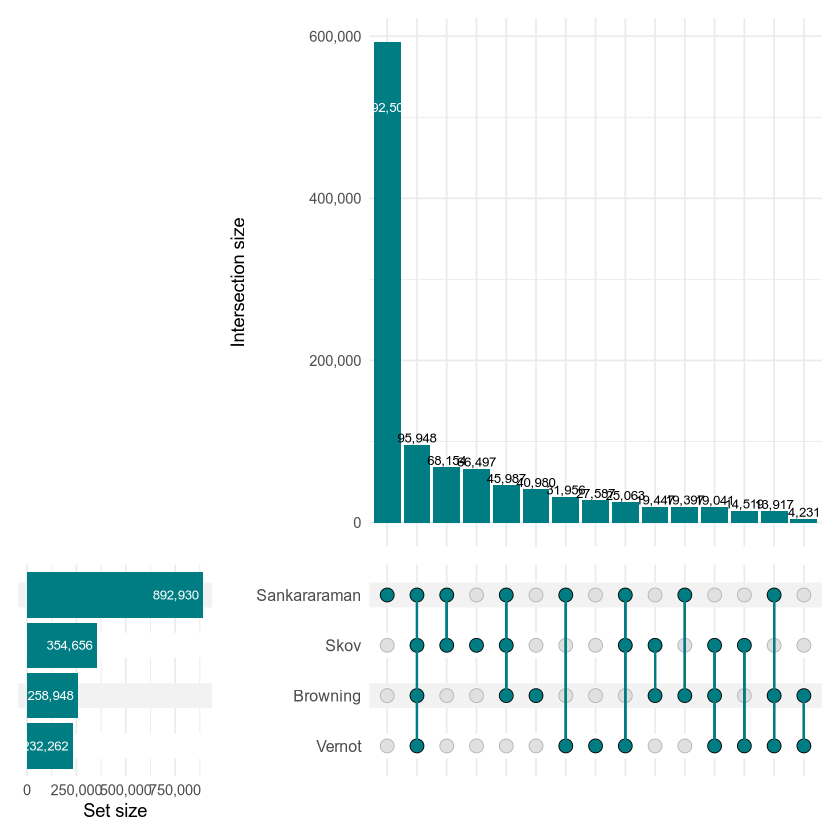

In [7]:
upset_themes <- upset_modify_themes(
  list(
    "Intersection size" = theme(
      text = element_text(family = "Arial", size = 11)
    ),
    "intersections_matrix" = theme(
      text = element_text(family = "Arial", size = 12)
    )
  )
)

neanderthal_variant_maps_upset_plot <- upset(
  data = neanderthal_map_memberships,
  intersect = neanderthal_maps,
  sort_sets = "descending",
  name = "",
  min_size = 0,
  height_ratio = 0.4,
  width_ratio = 0.3,
  matrix = intersection_matrix(
    geom = geom_point(size = 3),
    segment = geom_segment(colour = primary_colour, linewidth = 0.6)
  ) +
    scale_colour_manual(
      values = c("TRUE" = primary_colour, "FALSE" = "grey88"),
      guide = "none"
    ),
  base_annotations = list(
    "Intersection size" = intersection_size(
      fill = primary_colour,
      text = list(family = "Arial", size = 8 / .pt),
      text_mapping = aes(
        label = comma(!!get_size_mode("exclusive_intersection"))
      )
    ) +
      scale_y_continuous(labels = comma)
  ),
  set_sizes = upset_set_size(geom = geom_bar(fill = primary_colour)) +
    geom_text(
      aes(label = comma(after_stat(count))),
      stat = "count",
      hjust = 1.1,
      colour = "white",
      family = "Arial",
      size = 8 / .pt
    ) +
    scale_y_continuous(labels = comma),
  themes = upset_themes
)

neanderthal_variant_maps_upset_plot

In [8]:
save_pdf(
  neanderthal_variant_maps_upset_plot,
  file.path(
    supplementary_figures_directory, "neanderthal_variant_maps_upset.pdf"
  ),
  width = 12,
  height = 7
)

pdf 
  2

## 4. Neanderthal variant MAFs

gnomAD v4.1 minor allele frequency distributions at Neanderthal sites, with
the MAF > 1% threshold. Output:
`suppl_figs/gnomad_ancestry_group_neanderthal_variant_mafs.pdf`.

In [9]:
# "." marks a missing MAF, as in analysis.ipynb
gnomad_neanderthal_variant_mafs <- read_tsv(
  file.path(
    introgressed_variants_directory,
    "gnomAD_v4.1.0_introgressed_variant_MAFs.txt.gz"
  ),
  na = c("", "NA", "."),
  show_col_types = FALSE
) %>%
  rename_with(tolower)

maf_threshold <- 0.01

# Labels match analysis.ipynb
ancestry_labels <- c(
  maf_afr = "African/African American",
  maf_eas = "East Asian",
  maf_nfe = "Non-Finnish European",
  maf_sas = "South Asian"
)

head(gnomad_neanderthal_variant_mafs)

rsid,maf,maf_afr,maf_eas,maf_fin,maf_nfe,maf_sas
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
rs141945666,0.000440,0.000000,0.012722,0,0.000000,0
rs118163204,0.000007,0.000000,0.000000,0,0.000000,0
rs75104542,0.000512,0.000216,0.013112,0,0.000000,0
rs117994554,0.000486,0.000048,0.013712,0,0.000000,0
rs77476995,0.000525,0.000000,0.013873,0,0.000029,0
rs78387041,0.000007,0.000000,0.000000,0,0.000015,0


In [10]:
plot_gnomad_ancestry_group_neanderthal_variant_mafs <- function(
    variants, maf_column, ancestry_label) {
  n_non_rare_variants <- sum(variants[[maf_column]] > maf_threshold,
                             na.rm = TRUE)

  stat_label <- paste0(
    format(n_non_rare_variants, big.mark = ","), " variants with MAF > 1%"
  )

  ggplot(variants, aes(x = .data[[maf_column]])) +
    geom_density(adjust = 2, alpha = 0.75, fill = primary_colour) +
    geom_vline(
      xintercept = maf_threshold,
      colour = "black",
      linetype = "dashed",
      linewidth = hairline
    ) +
    annotate(
      "text",
      x = 0.5,
      y = Inf,
      label = stat_label,
      family = "Arial",
      hjust = 1,
      vjust = 5,
      size = 11 / .pt
    ) +
    labs(
      title = ancestry_label,
      x = paste0(
        ancestry_label, " Minor Allele Frequency at Neanderthal Sites"
      ),
      y = "Density"
    ) +
    scale_x_continuous(expand = expansion(mult = c(0, 0.05))) +
    scale_y_sqrt(expand = expansion(mult = c(0, 0.1))) +
    fig_theme +
    coord_cartesian(clip = "off") +
    theme(
      plot.title = element_text(hjust = 0.5),
      axis.text.y = element_blank(),
      axis.ticks.y = element_blank()
    )
}

maf_plots <- Map(
  function(maf_column, ancestry_label) {
    plot_gnomad_ancestry_group_neanderthal_variant_mafs(
      gnomad_neanderthal_variant_mafs, maf_column, ancestry_label
    )
  },
  names(ancestry_labels),
  ancestry_labels
)

Warning message:
“Removed 3 rows containing non-finite outside the scale range (`stat_density()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_density()`).”


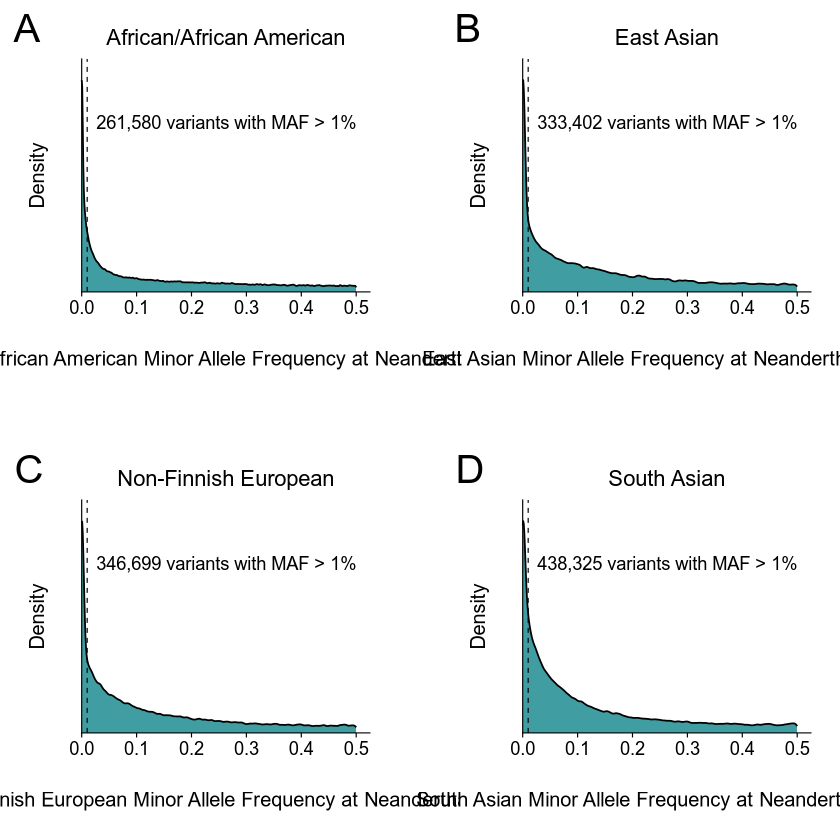

In [11]:
maf_row <- function(left, right, labels) {
  plot_grid_labelled(
    left,
    NULL,
    right,
    labels = c(labels[1], "", labels[2]),
    nrow = 1,
    rel_widths = c(0.475, 0.05, 0.475),
    scale = 0.9
  )
}

gnomad_ancestry_group_neanderthal_variant_mafs_plot <- plot_grid(
  maf_row(maf_plots$maf_afr, maf_plots$maf_eas, c("A", "B")),
  NULL,
  maf_row(maf_plots$maf_nfe, maf_plots$maf_sas, c("C", "D")),
  ncol = 1,
  rel_heights = c(0.475, 0.05, 0.475)
)

gnomad_ancestry_group_neanderthal_variant_mafs_plot

In [12]:
save_pdf(
  gnomad_ancestry_group_neanderthal_variant_mafs_plot,
  file.path(
    supplementary_figures_directory,
    "gnomad_ancestry_group_neanderthal_variant_mafs.pdf"
  ),
  width = 12,
  height = 12
)

pdf 
  2

## 5. GWAS loci with Neanderthal variants

### Example Manhattan plot and Neanderthal regions track

Chromosome 12 of the SCC GWAS above the Skov 2024 introgressed regions.
Output: `main_fig_components/example_manhattan_with_introgressed_regions.pdf`.

In [13]:
scc_chr12_pos_and_p_values <- read_tsv(
  file.path(
    gwas_summary_stats_directory,
    "squamous_cell_carcinoma_EUR_Seviiri_GCST90137412.txt.gz"
  ),
  col_select = c(chromosome, base_pair_location, p_value),
  show_col_types = FALSE
) %>%
  filter(chromosome == 12) %>%
  select(pos = base_pair_location, p_value)

nrow(scc_chr12_pos_and_p_values)

[1] 258807

In [14]:
# Non-significant points are thinned before plotting. A whole-chromosome panel
# has hundreds of thousands of variants, almost all of them noise, and a PDF
# that renders every one is slow to open without being more informative.
# Everything below p = 1e-2 is kept: that band is thin in the data, so
# thinning it at all empties the space between the noise cloud and the peaks.
# Above it the probability steps down gradually, because a single cliff
# leaves a visible horizontal seam where the density changes. The seed makes
# the thinning reproducible, so a rerun gives an identical figure.
set.seed(42)

hits_to_plot <- scc_chr12_pos_and_p_values %>%
  mutate(
    keep_probability = case_when(
      p_value < 1e-2 ~ 1,
      p_value < 1e-1 ~ 0.25,
      TRUE ~ 0.05
    ),
    random_value = runif(n())
  ) %>%
  filter(random_value <= keep_probability) %>%
  select(-keep_probability, -random_value)

panel_x_limits <- range(hits_to_plot$pos)

nrow(hits_to_plot)

[1] 24575

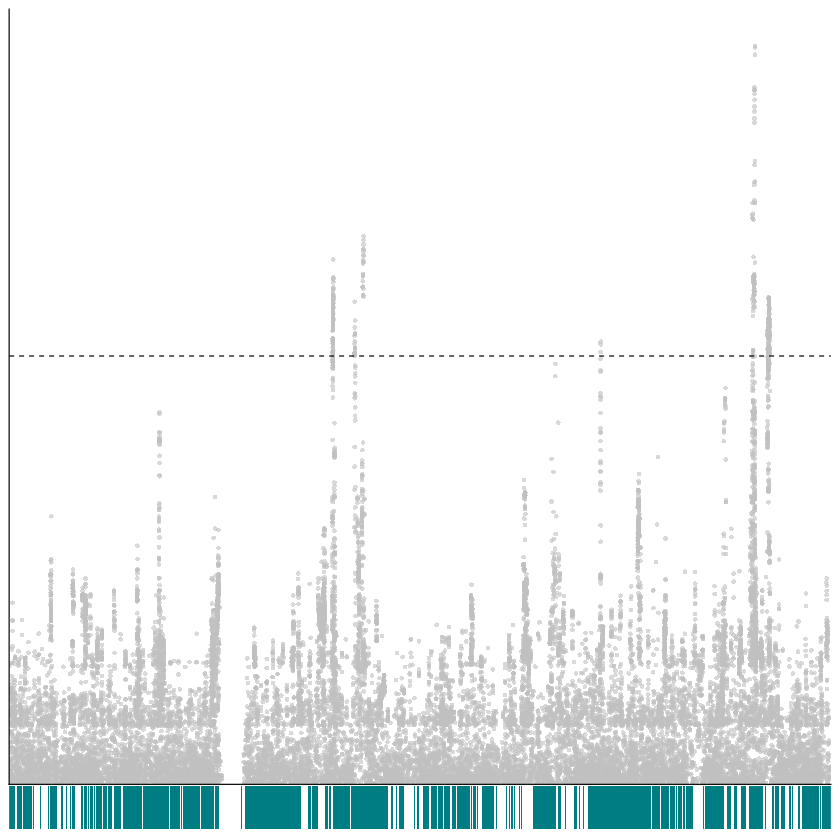

In [15]:
example_manhattan_plot <- ggplot(
  hits_to_plot,
  aes(x = pos, y = -log10(p_value))
) +
  geom_point(alpha = 0.6, colour = "grey75", shape = 16, size = 1) +
  geom_hline(
    yintercept = -log10(5e-8),
    colour = "black",
    linetype = "dashed",
    linewidth = hairline
  ) +
  scale_x_continuous(expand = c(0, 0)) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.05))) +
  coord_cartesian(xlim = panel_x_limits) +
  theme_classic() +
  theme(
    plot.margin = margin(0, 0, 0, 0),
    axis.line.x.bottom = element_line(linewidth = hairline),
    axis.line.y.left = element_line(linewidth = hairline),
    axis.title = element_blank(),
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    panel.grid = element_blank()
  )

skov_chr12_introgressed_regions <- read_tsv(
  file.path(
    introgressed_variants_directory, "Skov_2024_introgressed_regions_hg19.bed"
  ),
  col_names = c("chr", "start", "end"),
  col_types = "cii"
) %>%
  filter(chr == "12") %>%
  mutate(ymin = 0, ymax = 1)

skov_chr12_introgressed_regions_plot <- ggplot(
  skov_chr12_introgressed_regions
) +
  geom_rect(
    aes(xmin = start, xmax = end, ymin = ymin, ymax = ymax),
    fill = primary_colour
  ) +
  scale_x_continuous(expand = c(0, 0)) +
  coord_cartesian(xlim = panel_x_limits) +
  theme_void() +
  theme(plot.margin = margin(0, 0, 0, 0))

example_manhattan_with_introgressed_regions <- example_manhattan_plot /
  skov_chr12_introgressed_regions_plot +
  plot_layout(heights = c(1, 0.06))

example_manhattan_with_introgressed_regions

In [16]:
save_pdf(
  example_manhattan_with_introgressed_regions,
  file.path(
    main_figures_directory, "example_manhattan_with_introgressed_regions.pdf"
  ),
  width = 5,
  height = 1.5
)

pdf 
  2

### Proportion of GWAS loci with Neanderthal variants

From `proportion_loci_with_neanderthal_variants.txt`, written by
`analysis.ipynb`. Outputs:
`suppl_figs/proportion_gwas_loci_with_neanderthal_variants_all_r2.pdf` (all
three r² thresholds) and
`main_fig_components/proportion_gwas_loci_with_neanderthal_variants_r2_05.pdf`.

In [17]:
proportion_loci_with_neanderthal_variants <- read_tsv(
  file.path(
    supplementary_tables_directory,
    "proportion_loci_with_neanderthal_variants.txt"
  ),
  show_col_types = FALSE
)

head(proportion_loci_with_neanderthal_variants)

cancer,ancestry_group,author,gwas_id,r2,n_neanderthal,n_total,prop_neanderthal
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
breast_cancer,EAS,Jia,GCST90429846,0.2,3,41,0.07317073
breast_cancer,EAS,Jia,GCST90429846,0.5,3,68,0.04411765
breast_cancer,EAS,Jia,GCST90429846,0.8,5,125,0.04000000
colorectal_cancer,EAS,Lu,GCST009869,0.2,3,26,0.11538462
colorectal_cancer,EAS,Lu,GCST009869,0.5,3,34,0.08823529
colorectal_cancer,EAS,Lu,GCST009869,0.8,3,55,0.05454545


In [18]:
# One axis across all six panels, with room for the count labels at the end
# of the longest bar
proportion_axis_step <- 0.05
proportion_axis_breaks <- seq(
  0,
  ceiling(
    max(proportion_loci_with_neanderthal_variants$prop_neanderthal) /
      proportion_axis_step
  ) * proportion_axis_step,
  by = proportion_axis_step
)
proportion_axis_limit <- max(proportion_axis_breaks) + proportion_axis_step / 2

plot_proportion_loci_with_neanderthal_variants <- function(
    target_ancestry_group, target_r2) {
  # Cancers are ordered by their proportion at r2 = 0.5 within this ancestry
  # group, so a cancer sits at the same height across the three r2 panels of
  # a row while each row is ordered on its own data.
  cancer_order <- proportion_loci_with_neanderthal_variants %>%
    filter(
      ancestry_group == target_ancestry_group,
      r2 == 0.5,
      n_total > 0
    ) %>%
    arrange(prop_neanderthal) %>%
    pull(cancer)

  panel <- proportion_loci_with_neanderthal_variants %>%
    filter(
      ancestry_group == target_ancestry_group,
      r2 == target_r2,
      n_total > 0
    )

  bar_colour <- r2_colours[as.character(target_r2)]
  if (is.na(bar_colour)) stop("No colour defined for r2 = ", target_r2)

  ggplot(panel, aes(
    x = factor(cancer, levels = cancer_order),
    y = prop_neanderthal
  )) +
    geom_col(
      colour = "black",
      fill = bar_colour,
      linewidth = hairline,
      width = 0.8
    ) +
    geom_text(
      aes(label = comma(n_neanderthal)),
      hjust = -0.4,
      colour = "black",
      family = "Arial"
    ) +
    scale_x_discrete(labels = cancer_name_mappings) +
    scale_y_continuous(
      breaks = proportion_axis_breaks,
      expand = expansion(mult = c(0, 0))
    ) +
    fig_theme +
    theme(
      axis.title.x = element_blank(),
      axis.title.y = element_blank()
    ) +
    coord_flip(ylim = c(0, proportion_axis_limit))
}

In [19]:
eas_plot_r2_02 <- plot_proportion_loci_with_neanderthal_variants("EAS", 0.2)
eas_plot_r2_05 <- plot_proportion_loci_with_neanderthal_variants("EAS", 0.5)
eas_plot_r2_08 <- plot_proportion_loci_with_neanderthal_variants("EAS", 0.8)

eur_plot_r2_02 <- plot_proportion_loci_with_neanderthal_variants("EUR", 0.2)
eur_plot_r2_05 <- plot_proportion_loci_with_neanderthal_variants("EUR", 0.5)
eur_plot_r2_08 <- plot_proportion_loci_with_neanderthal_variants("EUR", 0.8)

count_cancers <- function(target_ancestry_group) {
  proportion_loci_with_neanderthal_variants %>%
    filter(ancestry_group == target_ancestry_group, r2 == 0.5, n_total > 0) %>%
    nrow()
}
n_eas_cancers <- count_cancers("EAS")
n_eur_cancers <- count_cancers("EUR")

# The title rows carry no axes, so they are sized in the same units as one
# cancer row
title_height <- 1

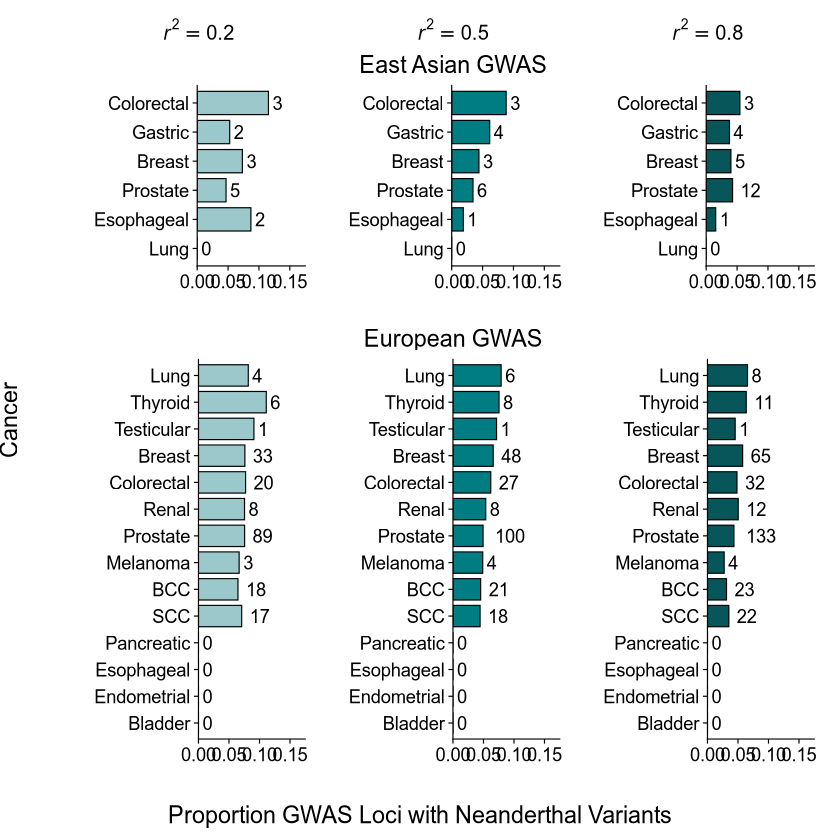

In [20]:
draw_r2_header <- function(value) {
  ggdraw() +
    draw_label(
      bquote(italic(r)^2 == .(value)),
      fontfamily = "Arial",
      fontface = "plain",
      size = 12
    )
}

row_title <- function(label) {
  ggdraw() +
    draw_label(label, fontfamily = "Arial", fontface = "plain", size = 14)
}

r2_row <- function(plot_02, plot_05, plot_08) {
  plot_grid(
    plot_02, NULL, plot_05, NULL, plot_08,
    ncol = 5,
    align = "h",
    axis = "bt",
    rel_widths = c(1, 0.1, 1, 0.1, 1)
  )
}

headers_row <- plot_grid(
  draw_r2_header(0.2),
  NULL,
  draw_r2_header(0.5),
  NULL,
  draw_r2_header(0.8),
  ncol = 5,
  rel_widths = c(1, 0.1, 1, 0.1, 1)
)

eas_title <- row_title("East Asian GWAS")
eur_title <- row_title("European GWAS")

# Each row needs one unit per cancer plus a constant for its x axis and
# margins, which do not shrink with the row; without the constant the
# shorter row's bars are squeezed and the two rows stop matching
all_r2_axis_overhead <- 3

all_r2_grid <- plot_grid(
  headers_row,
  NULL,
  eas_title,
  r2_row(eas_plot_r2_02, eas_plot_r2_05, eas_plot_r2_08),
  NULL,
  eur_title,
  r2_row(eur_plot_r2_02, eur_plot_r2_05, eur_plot_r2_08),
  ncol = 1,
  align = "v",
  rel_heights = c(
    1,
    0.4,
    title_height,
    n_eas_cancers + all_r2_axis_overhead,
    1,
    title_height,
    n_eur_cancers + all_r2_axis_overhead
  )
) +
  theme(plot.margin = margin(t = 10, r = 10, b = 40, l = 50))

proportion_gwas_loci_with_neanderthal_variants_all_r2_plot <-
  ggdraw(all_r2_grid) +
  draw_label(
    "Proportion GWAS Loci with Neanderthal Variants",
    x = 0.5,
    y = 0.02,
    vjust = 0,
    fontfamily = "Arial",
    fontface = "plain",
    size = 14
  ) +
  draw_label(
    "Cancer",
    x = 0.01,
    y = 0.5,
    angle = 90,
    fontfamily = "Arial",
    fontface = "plain",
    size = 14
  )

proportion_gwas_loci_with_neanderthal_variants_all_r2_plot

In [21]:
save_pdf(
  proportion_gwas_loci_with_neanderthal_variants_all_r2_plot,
  file.path(
    supplementary_figures_directory,
    "proportion_gwas_loci_with_neanderthal_variants_all_r2.pdf"
  ),
  width = 12,
  height = 15
)

pdf 
  2

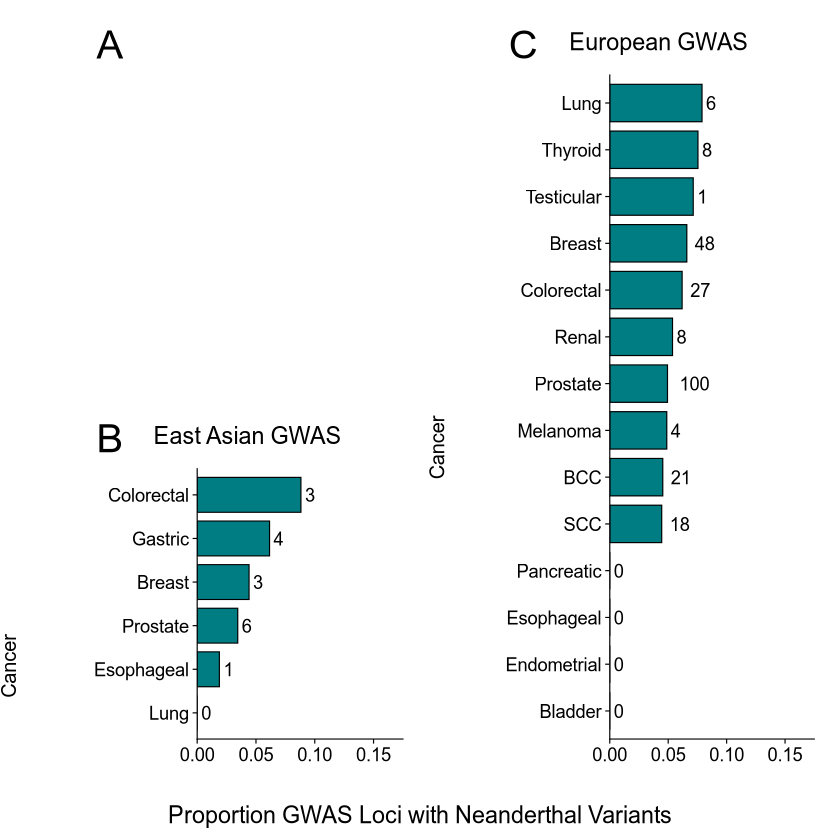

In [22]:
r2_05_axis_overhead <- 0.38

eas_block <- plot_grid(
  eas_title,
  eas_plot_r2_05,
  ncol = 1,
  rel_heights = c(title_height, n_eas_cancers + r2_05_axis_overhead)
)

eur_block <- plot_grid(
  eur_title,
  eur_plot_r2_05,
  ncol = 1,
  rel_heights = c(title_height, n_eur_cancers + r2_05_axis_overhead)
)

# C fills the right column, so the column height is its block. B is bottom
# anchored and sized to give its bars the same height as C's, which leaves A
# (a placeholder) the difference in cancer counts -- about 42% of the column.
eas_block_height <- title_height + n_eas_cancers + r2_05_axis_overhead
column_height <- title_height + n_eur_cancers + r2_05_axis_overhead

left_column <- plot_grid_labelled(
  NULL,
  eas_block,
  labels = c("A", "B"),
  ncol = 1,
  rel_heights = c(column_height - eas_block_height, eas_block_height)
)

right_column <- plot_grid_labelled(eur_block, labels = "C", ncol = 1)

proportion_loci_r2_05_grid <- plot_grid(
  left_column,
  NULL,
  right_column,
  nrow = 1,
  rel_widths = c(1, 0.25, 1)
) +
  theme(plot.margin = margin(t = 10, r = 10, b = 40, l = 50))

eas_label_centre <-
  (n_eas_cancers + r2_05_axis_overhead) / 2 / column_height
eur_label_centre <-
  (n_eur_cancers + r2_05_axis_overhead) / 2 / column_height

proportion_loci_r2_05_plot <- ggdraw(proportion_loci_r2_05_grid) +
  draw_label(
    "Cancer",
    x = 0.01,
    y = eas_label_centre,
    angle = 90,
    fontfamily = "Arial",
    fontface = "plain",
    size = 12
  ) +
  draw_label(
    "Cancer",
    x = 0.52,
    y = eur_label_centre,
    angle = 90,
    fontfamily = "Arial",
    fontface = "plain",
    size = 12
  ) +
  draw_label(
    "Proportion GWAS Loci with Neanderthal Variants",
    x = 0.5,
    y = 0.02,
    vjust = 0,
    fontfamily = "Arial",
    fontface = "plain",
    size = 14
  )

proportion_loci_r2_05_plot

In [23]:
save_pdf(
  proportion_loci_r2_05_plot,
  file.path(
    main_figures_directory,
    "proportion_gwas_loci_with_neanderthal_variants_r2_05.pdf"
  ),
  width = 12,
  height = 10
)

pdf 
  2

## 7. Neanderthal-majority signals

Posterior mass on Neanderthal variants and credible set size for each
Neanderthal-majority signal. Panel A is a placeholder. Output:
`main_fig_components/fine_mapping_summary.pdf`.

In [24]:
credible_set_genes <- read_tsv(
  prefer_current(file.path(fine_mapping_directory, "credible_set_genes.txt")),
  show_col_types = FALSE
)
deduplicated_credible_sets <- read_tsv(
  prefer_current(
    file.path(fine_mapping_directory, "credible_set_summary_deduplicated.txt")
  ),
  show_col_types = FALSE
)

neanderthal_signals <- deduplicated_credible_sets %>%
  filter(is_representative, genome_wide_significant, n_neanderthal >= 1)

# Should match n_neanderthal_gwas and n_neanderthal_majority in analysis.ipynb
c(
  signals = nrow(neanderthal_signals),
  majority = sum(neanderthal_signals$p_neanderthal > 0.5)
)

signals majority 
      70       32

In [25]:
majority_signals <- credible_set_genes %>%
  filter(p_neanderthal > 0.5) %>%
  mutate(
    cancer_label = short_cancer(cancer),
    plain_label = paste0(cancer_label, ": ", nearest_gene),
    suffix = if_else(
      duplicated(plain_label) | duplicated(plain_label, fromLast = TRUE),
      paste0(" (", ancestry_group, ")"),
      ""
    ),
    label = paste0(
      "'", cancer_label, ": '*italic('", nearest_gene, "')",
      if_else(suffix == "", "", paste0("*'", suffix, "'"))
    ),
    label = factor(label, levels = label[order(p_neanderthal)])
  )

nrow(majority_signals)

[1] 32

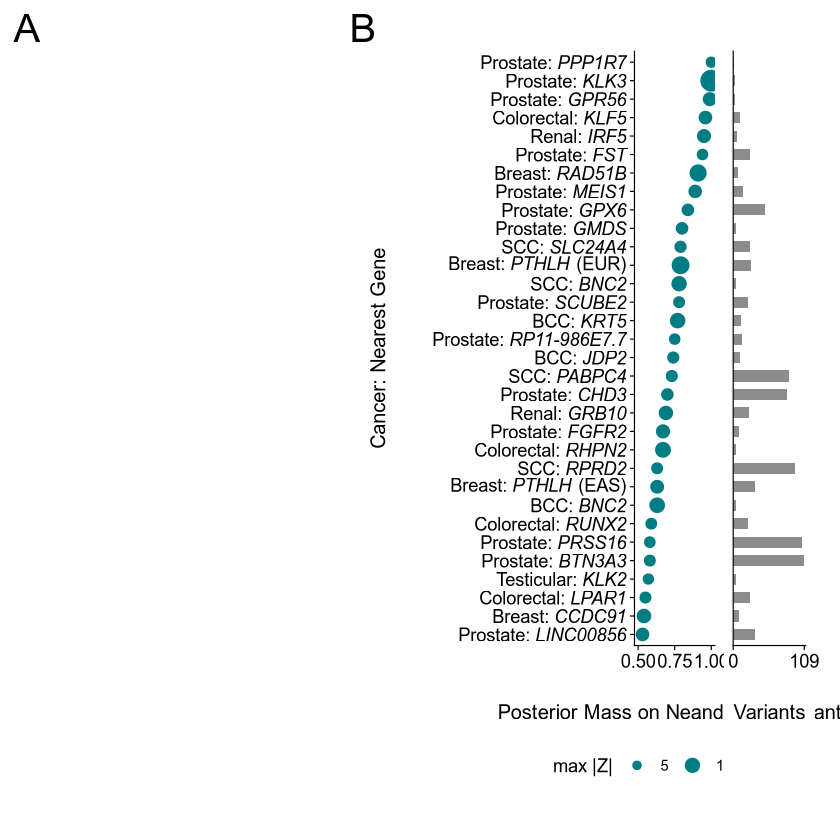

In [26]:
neanderthal_posterior_panel <- ggplot(
  majority_signals,
  aes(x = p_neanderthal, y = label)
) +
  geom_point(aes(size = max_abs_z), colour = primary_colour) +
  scale_x_continuous(breaks = seq(0.5, 1, 0.25)) +
  scale_y_discrete(labels = function(x) parse(text = x)) +
  scale_size_continuous(
    range = c(2, 5.5),
    limits = c(5, max(majority_signals$max_abs_z)),
    breaks = c(5, 10, 20, 28),
    name = "max |Z|"
  ) +
  labs(
    x = "Posterior Mass on Neanderthal Variants",
    y = "Cancer: Nearest Gene"
  ) +
  coord_cartesian(xlim = c(0.5, 1)) +
  fig_theme +
  theme(
    legend.position = "bottom",
    axis.text.y = element_text(size = 11)
  )

credible_set_size_panel <- ggplot(
  majority_signals,
  aes(x = n_variants, y = label)
) +
  geom_col(fill = "grey55", width = 0.6) +
  scale_x_continuous(
    expand = expansion(mult = c(0, 0.02)),
    breaks = c(0, max(majority_signals$n_variants))
  ) +
  labs(x = "Variants") +
  fig_theme +
  theme(
    axis.text.y = element_blank(),
    axis.title.y = element_blank(),
    axis.ticks.y = element_blank(),
    axis.line.y = element_blank()
  )

neanderthal_signals_plot <- plot_grid(
  neanderthal_posterior_panel,
  credible_set_size_panel,
  nrow = 1,
  rel_widths = c(0.8, 0.2),
  align = "h",
  axis = "tb"
)

fine_mapping_summary_plot <- plot_grid(
  plot_grid_labelled(NULL, labels = "A", nrow = 1, scale = 0.9),
  plot_grid_labelled(
    neanderthal_signals_plot, labels = "B", nrow = 1, scale = 0.9
  ),
  nrow = 1,
  rel_widths = c(0.4, 0.6)
)

fine_mapping_summary_plot

In [27]:
save_pdf(
  fine_mapping_summary_plot,
  file.path(main_figures_directory, "fine_mapping_summary.pdf"),
  width = 12,
  height = 10
)

pdf 
  2

## 9. Locus examples

Locuszoom, PIP, allele frequency, Open Targets and eQTL panels for the
Neanderthal-majority examples. eQTL panels use per-sample GTEx data
retrieved by `scripts/eQTL/retrieve_gtex_eqtls.py`. The locuszoom and PIP helpers are sourced from
`scripts/notebooks/` on Wynton. The *KRT* cluster (9.2) has no figure.

In [28]:
source(file.path(notebooks_directory, "generate_locuszoom_plot.R"))
source(file.path(notebooks_directory, "locuszoom_helpers.R"))
source(file.path(notebooks_directory, "plot_credible_set_pips.R"))

In [29]:
plot_allele_frequencies <- function(frequencies,
                                    variant,
                                    fill = primary_colour,
                                    x_label = "1KG Continental Group",
                                    y_label = "Neanderthal Allele Frequency") {
  if (!is.data.frame(frequencies)) {
    if (is.null(names(frequencies))) {
      stop(
        "Pass either a named vector of frequencies, or a data frame with ",
        "ancestry_group and AF columns."
      )
    }
    frequencies <- tibble(
      ancestry_group = names(frequencies),
      AF = as.numeric(frequencies)
    )
  }

  missing_columns <- setdiff(c("ancestry_group", "AF"), names(frequencies))
  if (length(missing_columns) > 0) {
    stop(
      "frequencies is missing the ",
      paste(missing_columns, collapse = " and "),
      " column(s)."
    )
  }

  ggplot(frequencies, aes(x = reorder(ancestry_group, AF), y = AF)) +
    geom_col(
      fill = fill,
      colour = "black",
      linewidth = hairline,
      width = 0.6
    ) +
    geom_text(
      aes(label = round(AF, 3)),
      family = "Arial",
      hjust = -0.2,
      size = 11 / .pt
    ) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.3))) +
    labs(x = x_label, y = y_label, title = variant) +
    coord_flip() +
    fig_theme +
    theme(
      plot.margin = margin(t = 5, r = 5, b = 5, l = 5),
      plot.title = element_text(
        hjust = 0.5,
        size = 12,
        margin = margin(b = 20)
      )
    )
}

In [30]:
# GTEx eQTL results from scripts/eQTL/retrieve_gtex_eqtls.py, every effect
# oriented to the allele of interest in eqtl_config.yaml. Set this to the
# folder of the GTEx release used: v10 matches the sample sizes of the earlier
# rs788464 panel (n = 816 in skeletal muscle; v8 has 706).
eqtl_directory <- file.path(data_directory, "eQTL", "gtex_v10")

# pandas writes True/False; make sure flag columns are logical either way
as_flag <- function(x) as.logical(toupper(as.character(x)))

significant_eqtls <- read_tsv(
  file.path(eqtl_directory, "gtex_significant_eqtls.txt"),
  show_col_types = FALSE
) %>%
  mutate(is_gtex_lead = as_flag(is_gtex_lead))

focus_gene_eqtls <- read_tsv(
  file.path(eqtl_directory, "gtex_focus_gene_effects.txt"),
  show_col_types = FALSE
) %>%
  mutate(significant = as_flag(significant))

expression_by_genotype <- read_tsv(
  file.path(eqtl_directory, "gtex_expression_by_genotype.txt.gz"),
  show_col_types = FALSE
)

count(significant_eqtls, dataset, locus, rsID, allele, is_gtex_lead)

dataset,locus,rsID,allele,is_gtex_lead,n
<chr>,<chr>,<chr>,<chr>,<lgl>,<int>
gtex_v10,PTHLH,rs10843134,G,FALSE,89
gtex_v10,PTHLH,rs788464,G,FALSE,2
gtex_v10,SLC24A4,rs12435365,G,FALSE,1
gtex_v10,SLC24A4,rs79342051,T,FALSE,1


In [31]:
# "Breast_Mammary_Tissue" -> "Breast - Mammary Tissue", as on the GTEx portal
tissue_label <- function(tissue) {
  str_replace_all(str_replace(tissue, "_", " - "), "_", " ")
}

# Genotype labels from a GTEx variant ID (chr_pos_ref_alt_b38), ordered by
# copies of the allele of interest: other/other, other/allele, allele/allele
genotype_labels <- function(variant_id, allele) {
  other <- setdiff(str_split_fixed(variant_id, "_", 5)[1, 3:4], allele)
  paste0(c(other, other, allele), "/", c(other, allele, allele))
}

with_confidence_interval <- function(eqtls) {
  mutate(
    eqtls,
    ci_low = nes - qnorm(0.975) * se,
    ci_high = nes + qnorm(0.975) * se
  )
}

In [32]:
# Per-sample expression by genotype for one variant-gene-tissue pair. Groups
# of fewer than 10 samples are drawn as points rather than a violin and box,
# which would misrepresent a handful of samples.
plot_expression_by_genotype <- function(target_rsid,
                                        target_gene,
                                        target_tissue,
                                        colour = primary_colour,
                                        min_violin_size = 10) {
  pair <- expression_by_genotype %>%
    filter(
      rsID == target_rsid,
      gene_symbol == target_gene,
      tissue == target_tissue
    )
  statistics <- significant_eqtls %>%
    filter(
      rsID == target_rsid,
      gene_symbol == target_gene,
      tissue == target_tissue
    )
  if (nrow(pair) == 0 || nrow(statistics) != 1) {
    stop(
      target_rsid, " is not a significant eQTL for ", target_gene, " in ",
      target_tissue, " in this GTEx release."
    )
  }

  allele <- statistics$allele
  group_sizes <- tabulate(pair$copies_of_allele + 1, nbins = 3)
  tick_labels <- sprintf(
    "%s\n(n = %s)",
    genotype_labels(statistics$variant_id, allele),
    format(group_sizes, big.mark = ",", trim = TRUE)
  )

  pair <- pair %>%
    mutate(
      genotype = factor(copies_of_allele, levels = 0:2, labels = tick_labels)
    ) %>%
    add_count(genotype, name = "group_size")
  large_groups <- filter(pair, group_size >= min_violin_size)
  small_groups <- filter(pair, group_size < min_violin_size)

  ggplot(pair, aes(x = genotype, y = expression)) +
    geom_violin(
      data = large_groups,
      fill = colour,
      colour = NA,
      alpha = 0.35,
      scale = "width"
    ) +
    geom_boxplot(
      data = large_groups,
      width = 0.15,
      outlier.shape = NA,
      fill = "white",
      linewidth = hairline
    ) +
    geom_point(
      data = small_groups,
      colour = colour,
      size = 2,
      position = position_jitter(width = 0.08, height = 0, seed = 1)
    ) +
    scale_x_discrete(drop = FALSE) +
    labs(
      x = paste0(target_rsid, " Genotype"),
      y = "Normalized Expression",
      title = bquote(italic(.(target_gene))),
      subtitle = sprintf(
        "%s\nNES = %.2f, P = %.1e",
        tissue_label(target_tissue), statistics$nes, statistics$p_value
      )
    ) +
    fig_theme +
    theme(
      plot.title = element_text(hjust = 0.5, size = 12),
      plot.subtitle = element_text(
        hjust = 0.5,
        size = 11,
        colour = "grey35",
        margin = margin(b = 15)
      )
    )
}

In [33]:
# Every significant eQTL for a set of variants, one row per gene-tissue pair,
# grouped by credible set signal. Breast and adipose tissue are highlighted.
plot_significant_eqtls <- function(eqtls,
                                   x_label = "Normalized Effect Size",
                                   highlight = "^(Breast|Adipose)") {
  eqtls <- eqtls %>%
    with_confidence_interval() %>%
    mutate(
      signal_label = paste0(rsID, "\n", str_extract(signal, "CS\\d+")),
      highlighted = str_detect(tissue, highlight),
      # rsID keeps rows distinct when both variants affect the same pair
      row_id = paste0(
        "<i>", gene_symbol, "</i> · ", tissue_label(tissue), "||", rsID
      )
    ) %>%
    arrange(signal_label, nes) %>%
    mutate(row_id = factor(row_id, levels = unique(row_id)))

  ggplot(eqtls, aes(x = nes, y = row_id)) +
    geom_vline(xintercept = 0, colour = "grey60", linewidth = hairline) +
    geom_errorbar(
      aes(xmin = ci_low, xmax = ci_high),
      width = 0,
      colour = "grey40",
      linewidth = hairline,
      orientation = "y"
    ) +
    geom_point(aes(fill = highlighted), shape = 21, size = 1.8) +
    scale_fill_manual(
      values = c(`TRUE` = primary_colour, `FALSE` = "grey85"),
      labels = c(`TRUE` = "Adipose or Breast", `FALSE` = "Other tissue"),
      name = NULL
    ) +
    scale_y_discrete(labels = function(x) str_remove(x, "\\|\\|.*$")) +
    facet_grid(signal_label ~ ., scales = "free_y", space = "free_y") +
    labs(x = x_label, y = NULL) +
    fig_theme +
    theme(
      axis.text.y = element_markdown(size = 9),
      legend.position = "bottom",
      strip.background = element_blank(),
      strip.text.y = element_text(angle = 0, hjust = 0, size = 10)
    )
}

# Effect of each variant on each focus gene in every tissue, significant or
# not; dots mark significant eQTLs and grey tiles pairs GTEx did not test.
plot_focus_gene_heatmap <- function(effects) {
  nes_limit <- max(abs(effects$nes), na.rm = TRUE)
  tissue_names <- sort(unique(tissue_label(effects$tissue)))

  effects <- effects %>%
    mutate(
      tissue_name = factor(tissue_label(tissue), levels = rev(tissue_names)),
      signal_label = paste0(rsID, "\n", str_extract(signal, "CS\\d+"))
    )

  ggplot(effects, aes(x = gene_symbol, y = tissue_name, fill = nes)) +
    geom_tile(colour = "white", linewidth = 0.3) +
    geom_point(
      data = filter(effects, significant),
      shape = 16,
      size = 1.2,
      colour = "black"
    ) +
    scale_fill_gradient2(
      low = "#B2182B",
      mid = "#F7F7F7",
      high = "#2166AC",
      midpoint = 0,
      limits = c(-nes_limit, nes_limit),
      na.value = "grey92",
      name = "NES"
    ) +
    facet_grid(. ~ signal_label) +
    labs(x = NULL, y = NULL) +
    fig_theme +
    theme(
      axis.line = element_blank(),
      axis.ticks = element_blank(),
      axis.text.x = element_text(face = "italic", angle = 45, hjust = 1),
      axis.text.y = element_text(size = 8),
      strip.background = element_blank()
    )
}

# Effect of one variant on one gene across tissues, ordered by effect size
plot_tissue_effects <- function(effects,
                                colour = primary_colour,
                                x_label = "Normalized Effect Size") {
  effects <- effects %>%
    filter(!is.na(nes)) %>%
    with_confidence_interval() %>%
    mutate(tissue_name = reorder(tissue_label(tissue), nes))

  ggplot(effects, aes(x = nes, y = tissue_name)) +
    geom_vline(xintercept = 0, colour = "grey60", linewidth = hairline) +
    geom_errorbar(
      aes(xmin = ci_low, xmax = ci_high),
      width = 0,
      colour = "grey40",
      linewidth = hairline,
      orientation = "y"
    ) +
    geom_point(aes(fill = significant), shape = 21, size = 2.2) +
    scale_fill_manual(
      values = c(`TRUE` = colour, `FALSE` = "white"),
      labels = c(`TRUE` = "Significant eQTL", `FALSE` = "Not significant"),
      name = NULL
    ) +
    labs(x = x_label, y = NULL) +
    fig_theme +
    theme(axis.text.y = element_text(size = 8), legend.position = "bottom")
}

### 9.1 *BNC2*

Outputs: `main_fig_components/bnc2_scc_fine_mapping_example.pdf` (SCC) and
`suppl_figs/bnc2_bcc_fine_mapping_example.pdf` (BCC).

squamous_cell_carcinoma_EUR_Seviiri_GCST90137412 | EUR | 9_16800341 | L2

  index variant: rs2026805 (chr9:16,800,789, PIP 0.621)

  credible set:  4 variants, 2 introgressed, spanning 6 kb

  also at locus: L1, 6 variants, lead rs10810650 (chr9:16,873,551, PIP 0.373)

  sumstats:      squamous_cell_carcinoma_EUR_Seviiri_GCST90137412.txt.gz

  columns:       chromosome / base_pair_location / p_value / variant_id

Warning message in `[.data.table`(gff, , `:=`(gene_name, str_extract(attr, "(?<=gene_name=)[^;]+"))):
“A shallow copy of this data.table was taken so that := can add or remove 1 columns by reference. At an earlier point, this data.table was copied by R (or was created manually using structure() or similar). Avoid names<- and attr<- which in R currently (and oddly) may copy the whole data.table. Use set* syntax instead to avoid copying: ?set, ?setnames and ?setattr. It's also not unusual for data.table-agnostic packages to produce tables affected by this issue. If this message 

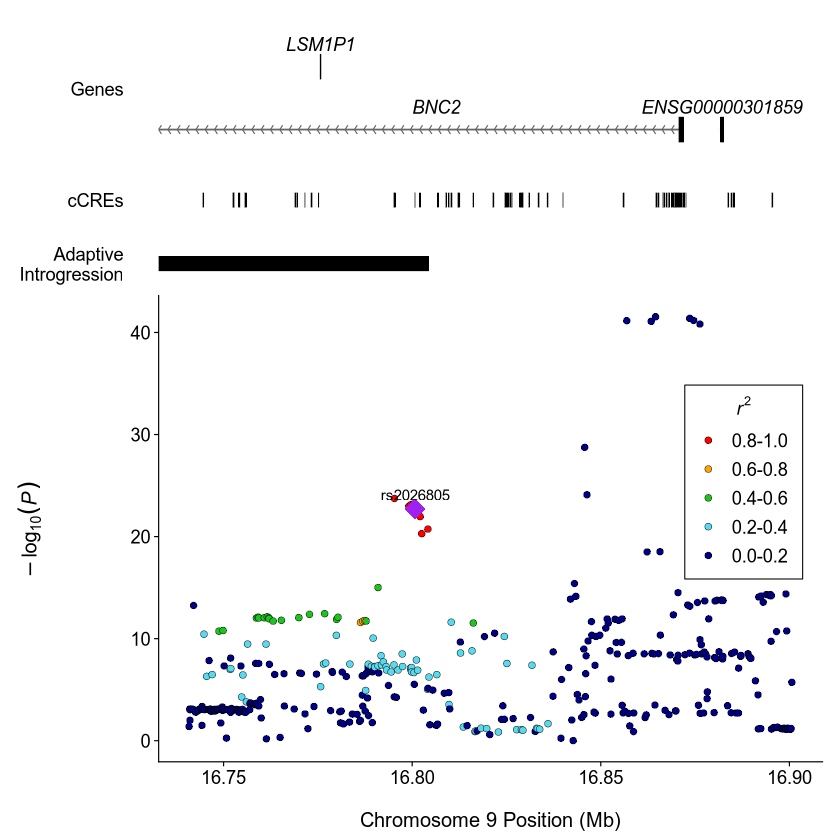

In [34]:
scc_gwas <- "squamous_cell_carcinoma_EUR_Seviiri_GCST90137412"
bcc_gwas <- "basal_cell_carcinoma_EUR_Seviiri_GCST90137411"
bnc2_locus <- "9_16800341"

bnc2_scc_locuszoom_plot <- locuszoom_for_credible_set(
  cancer = scc_gwas,
  ancestry_group = "EUR",
  locus_id = bnc2_locus,
  credible_set = "L2",
  upstream_kb = 60,
  downstream_kb = 100
)

bnc2_scc_locuszoom_plot

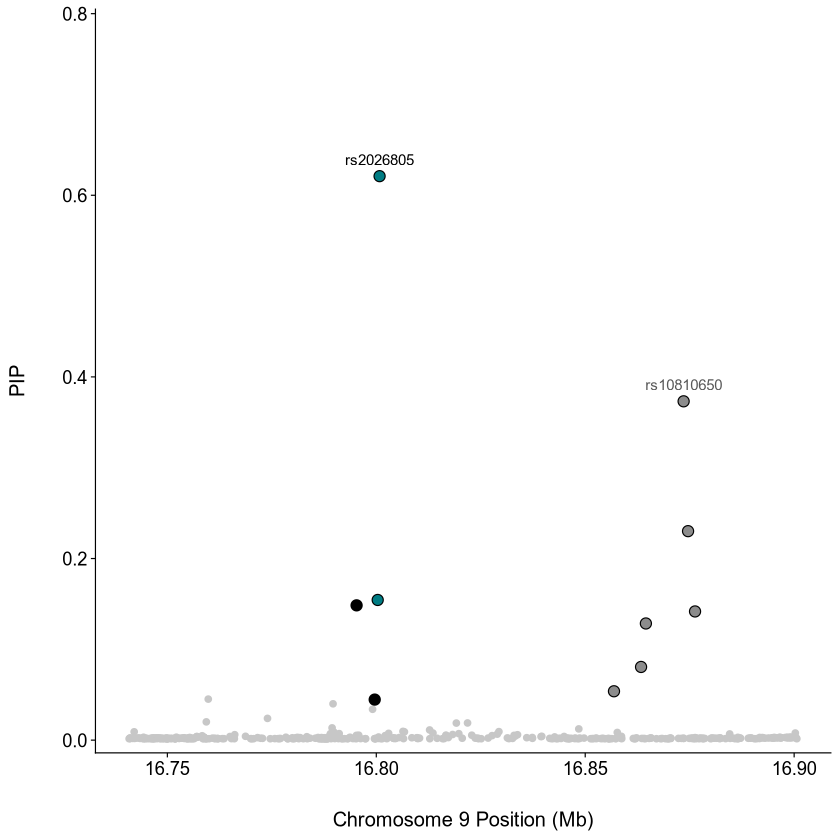

In [35]:
bnc2_scc_pips_plot <- plot_credible_set_pips(
  result_file = fine_mapping_result_file(scc_gwas, bnc2_locus, "EUR"),
  highlight_cs = "L2",
  index_snv = "rs2026805",
  upstream_kb = 60,
  downstream_kb = 100
)

bnc2_scc_pips_plot

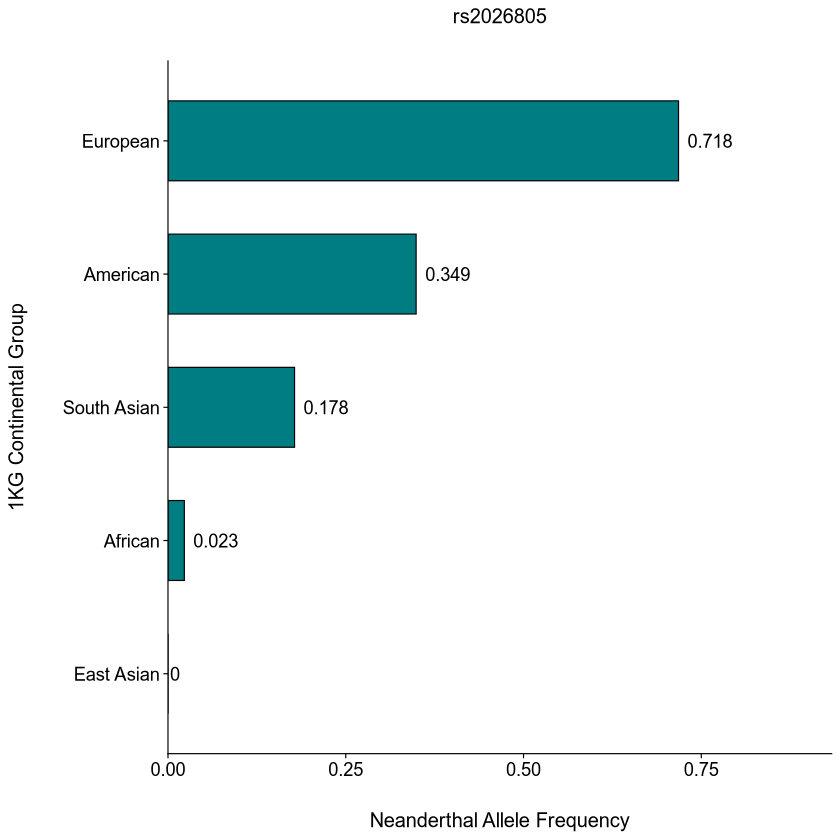

In [36]:
# 1000 Genomes Phase 3 continental-group frequencies of the Neanderthal allele
rs2026805_afs_plot <- plot_allele_frequencies(
  c(
    African = 0.023,
    American = 0.349,
    `East Asian` = 0,
    European = 0.718,
    `South Asian` = 0.178
  ),
  "rs2026805"
)

rs2026805_afs_plot

In [37]:
# Open Targets credible sets that contain rs2026805, from the same table as
# Table S9 and analysis.ipynb. Traits that are neither pigmentation nor skin
# cancer are dropped, since the panel is about the pigmentation-to-cancer
# relationship.
bnc2_open_targets <- read_tsv(
  file.path(open_targets_directory, "open_targets_bnc2_cs.txt"),
  show_col_types = FALSE
)

excluded_traits <- c(
  "Primary open angle glaucoma (PheCode 365.11)",
  "Hypertension",
  "Hallux valgus (Bunion) (PheCode 735.3)"
)

rs2026805_open_targets_effects <- bnc2_open_targets %>%
  filter(rsID == "rs2026805", !`Reported Trait` %in% excluded_traits) %>%
  distinct(`Open Targets Study Locus ID`, .keep_all = TRUE) %>%
  mutate(
    beta = `Lead Variant Beta`,
    trait_group = factor(
      if_else(
        str_detect(`Reported Trait`, "Hair colour"),
        "Hair color",
        "Skin cancer"
      ),
      levels = c("Hair color", "Skin cancer")
    ),
    label = str_remove(
      str_remove(`Reported Trait`, "Hair colour.*: "), " \\(.*"
    ),
    label = recode(
      label,
      "Melanomas of skin, dx or hx" = "Melanoma",
      "Neoplasm of uncertain behavior of skin" = "Uncertain skin neoplasm"
    ),
    label = reorder(label, beta)
  )

# Seven points: three hair colours and four skin cancers
nrow(rs2026805_open_targets_effects)

[1] 7

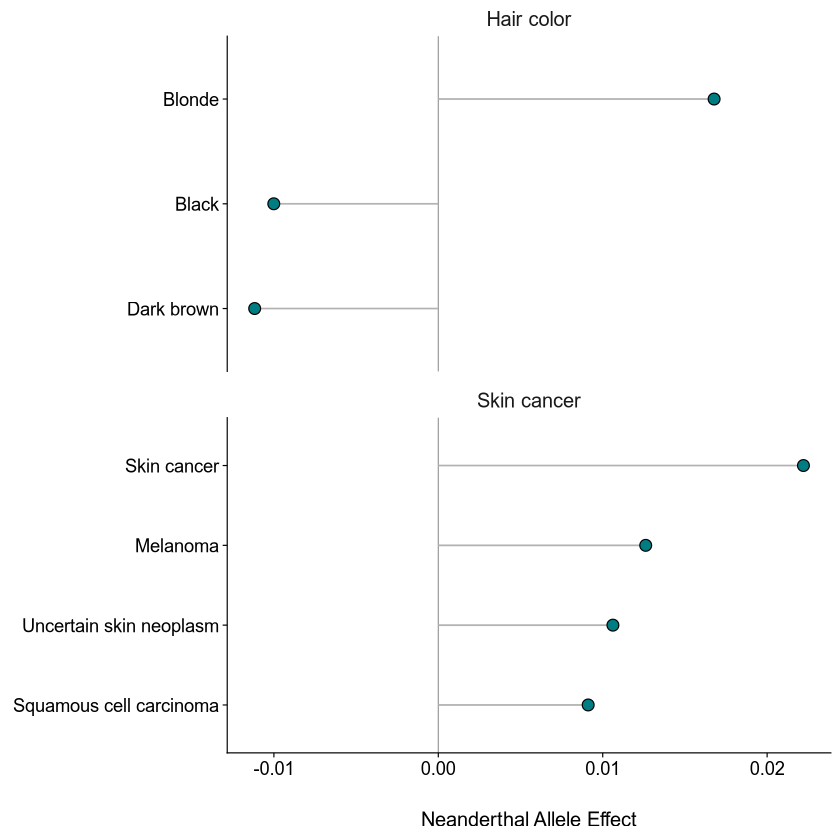

In [38]:
rs2026805_open_targets_effects_plot <- ggplot(
  rs2026805_open_targets_effects,
  aes(x = beta, y = label)
) +
  geom_vline(xintercept = 0, colour = "grey60", linewidth = hairline) +
  geom_segment(aes(x = 0, xend = beta, yend = label), colour = "grey70") +
  geom_point(shape = 21, size = 3, fill = primary_colour, colour = "black") +
  facet_wrap(
    ~ trait_group, ncol = 1, scales = "free_y", strip.position = "top"
  ) +
  labs(x = "Neanderthal Allele Effect", y = NULL) +
  fig_theme +
  theme(
    strip.background = element_blank(),
    strip.text = element_text(
      size = 12,
      hjust = 0.5,
      margin = margin(b = 5)
    ),
    panel.spacing.y = unit(0.8, "lines")
  )

rs2026805_open_targets_effects_plot

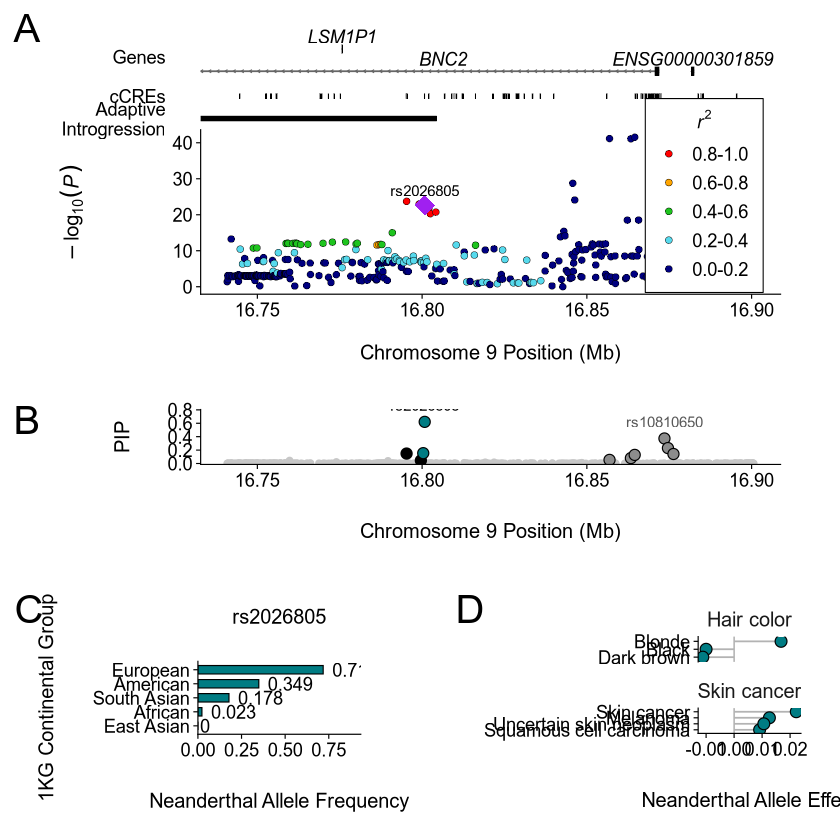

In [39]:
bnc2_scc_bottom_row <- plot_grid_labelled(
  rs2026805_afs_plot,
  NULL,
  rs2026805_open_targets_effects_plot,
  labels = c("C", "", "D"),
  nrow = 1,
  rel_widths = c(0.475, 0.05, 0.475),
  scale = 0.85
)

# rel_heights in inches on a 12 inch page, so the locuszoom and PIPs panels
# come out the same physical size as in the supplementary figures
bnc2_scc_fine_mapping_example_plot <- plot_grid(
  stack_locuszoom_and_pips(bnc2_scc_locuszoom_plot, bnc2_scc_pips_plot),
  NULL,
  bnc2_scc_bottom_row,
  ncol = 1,
  rel_heights = c(8.0, 0.3, 3.7)
)

bnc2_scc_fine_mapping_example_plot

In [40]:
save_pdf(
  bnc2_scc_fine_mapping_example_plot,
  file.path(main_figures_directory, "bnc2_scc_fine_mapping_example.pdf"),
  width = 12,
  height = 12
)

pdf 
  2

basal_cell_carcinoma_EUR_Seviiri_GCST90137411 | EUR | 9_16800341 | L2

  index variant: rs2026805 (chr9:16,800,789, PIP 0.403)

  credible set:  5 variants, 2 introgressed, spanning 6 kb

  also at locus: L1, 6 variants, lead rs2153271 (chr9:16,864,521, PIP 0.282)

  also at locus: L3, 21 variants, lead rs10962511 (chr9:16,613,687, PIP 0.339)

  also at locus: L4, 2 variants, lead rs141457510 (chr9:16,489,760, PIP 0.526)

  also at locus: L5, 3 variants, lead rs10120880 (chr9:16,821,840, PIP 0.727)

  also at locus: L6, 14 variants, lead rs73417442 (chr9:16,518,895, PIP 0.200)

  also at locus: L7, 15 variants, lead rs16934786 (chr9:16,526,910, PIP 0.393)

  sumstats:      basal_cell_carcinoma_EUR_Seviiri_GCST90137411.txt.gz

  columns:       chromosome / base_pair_location / p_value / variant_id

Warning message in `[.data.table`(gff, , `:=`(gene_name, str_extract(attr, "(?<=gene_name=)[^;]+"))):
“A shallow copy of this data.table was taken so that := can add or remove 1 columns by re

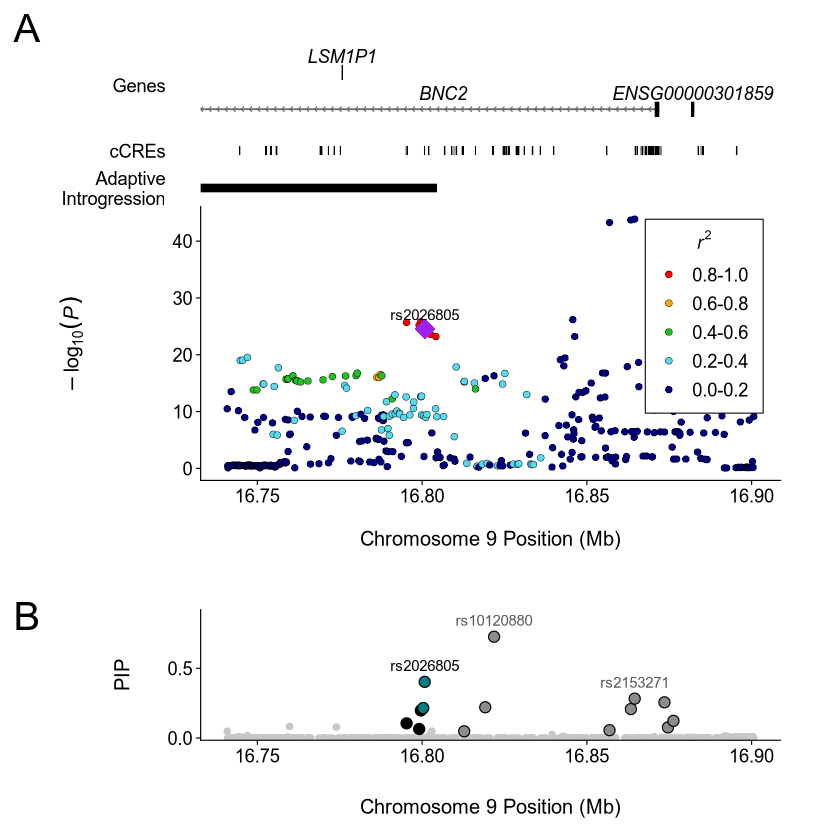

In [41]:
bnc2_bcc_locuszoom_plot <- locuszoom_for_credible_set(
  cancer = bcc_gwas,
  ancestry_group = "EUR",
  locus_id = bnc2_locus,
  credible_set = "L2",
  upstream_kb = 60,
  downstream_kb = 100
)

bnc2_bcc_pips_plot <- plot_credible_set_pips(
  result_file = fine_mapping_result_file(bcc_gwas, bnc2_locus, "EUR"),
  highlight_cs = "L2",
  index_snv = "rs2026805",
  upstream_kb = 60,
  downstream_kb = 100
)

bnc2_bcc_fine_mapping_example_plot <- stack_locuszoom_and_pips(
  bnc2_bcc_locuszoom_plot, bnc2_bcc_pips_plot
)

bnc2_bcc_fine_mapping_example_plot

In [42]:
save_pdf(
  bnc2_bcc_fine_mapping_example_plot,
  file.path(
    supplementary_figures_directory, "bnc2_bcc_fine_mapping_example.pdf"
  ),
  width = 12,
  height = 8
)

pdf 
  2

### 9.3 *PABPC4*

Output: `suppl_figs/pabpc4_fine_mapping_example.pdf`.

squamous_cell_carcinoma_EUR_Seviiri_GCST90137412 | EUR | 1_40035928 | L1

  index variant: rs3768321 (chr1:40,035,928, PIP 0.334)

  credible set:  85 variants, 60 introgressed, spanning 523 kb

  sumstats:      squamous_cell_carcinoma_EUR_Seviiri_GCST90137412.txt.gz

  columns:       chromosome / base_pair_location / p_value / variant_id

Warning message in `[.data.table`(gff, , `:=`(gene_name, str_extract(attr, "(?<=gene_name=)[^;]+"))):
“A shallow copy of this data.table was taken so that := can add or remove 1 columns by reference. At an earlier point, this data.table was copied by R (or was created manually using structure() or similar). Avoid names<- and attr<- which in R currently (and oddly) may copy the whole data.table. Use set* syntax instead to avoid copying: ?set, ?setnames and ?setattr. It's also not unusual for data.table-agnostic packages to produce tables affected by this issue. If this message doesn't help, please report your use case to the data.table issue tracker s

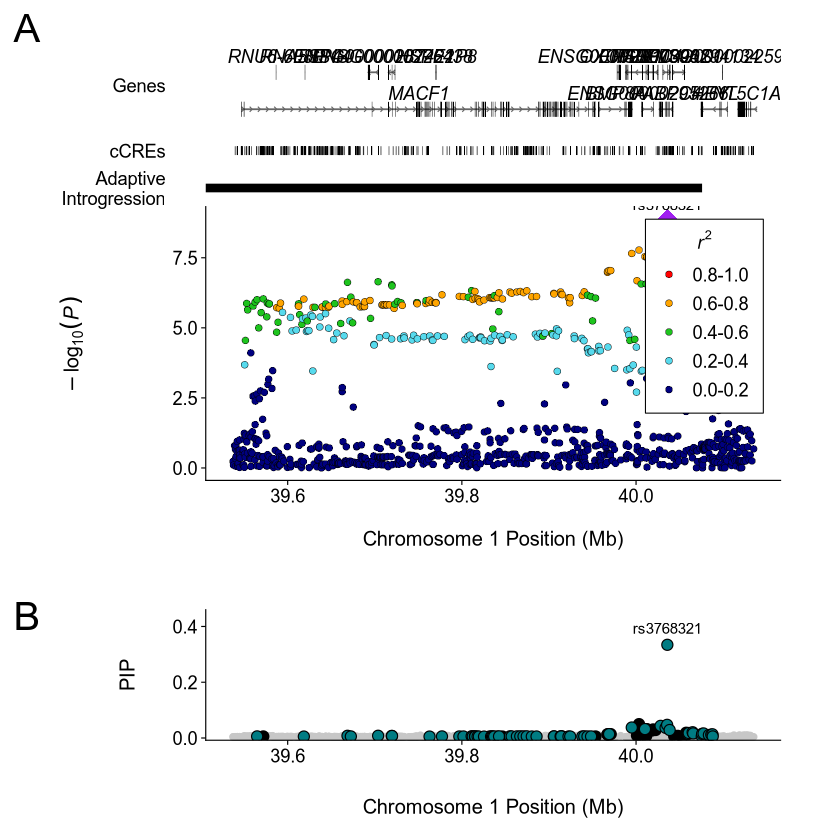

In [43]:
pabpc4_locus <- "1_40035928"

pabpc4_locuszoom_plot <- locuszoom_for_credible_set(
  cancer = scc_gwas,
  ancestry_group = "EUR",
  locus_id = pabpc4_locus,
  credible_set = "L1",
  upstream_kb = 500,
  downstream_kb = 100
)

pabpc4_pips_plot <- plot_credible_set_pips(
  result_file = fine_mapping_result_file(scc_gwas, pabpc4_locus, "EUR"),
  highlight_cs = "L1",
  upstream_kb = 500,
  downstream_kb = 100
)

pabpc4_fine_mapping_example_plot <- stack_locuszoom_and_pips(
  pabpc4_locuszoom_plot, pabpc4_pips_plot
)

pabpc4_fine_mapping_example_plot

In [44]:
save_pdf(
  pabpc4_fine_mapping_example_plot,
  file.path(
    supplementary_figures_directory, "pabpc4_fine_mapping_example.pdf"
  ),
  width = 12,
  height = 8
)

pdf 
  2

### 9.4 *SLC24A4*

Outputs: `suppl_figs/slc24a4_fine_mapping_example.pdf` and
`suppl_figs/slc24a4_eqtls.pdf`.

squamous_cell_carcinoma_EUR_Seviiri_GCST90137412 | EUR | 14_92773295 | L1

  index variant: rs1957283 (chr14:92,767,680, PIP 0.129)

  credible set:  25 variants, 21 introgressed, spanning 39 kb

  also at locus: L2, 3 variants, lead rs10873421 (chr14:92,818,731, PIP 0.393)

  sumstats:      squamous_cell_carcinoma_EUR_Seviiri_GCST90137412.txt.gz

  columns:       chromosome / base_pair_location / p_value / variant_id

Warning message in `[.data.table`(gff, , `:=`(gene_name, str_extract(attr, "(?<=gene_name=)[^;]+"))):
“A shallow copy of this data.table was taken so that := can add or remove 1 columns by reference. At an earlier point, this data.table was copied by R (or was created manually using structure() or similar). Avoid names<- and attr<- which in R currently (and oddly) may copy the whole data.table. Use set* syntax instead to avoid copying: ?set, ?setnames and ?setattr. It's also not unusual for data.table-agnostic packages to produce tables affected by this issue. If this me

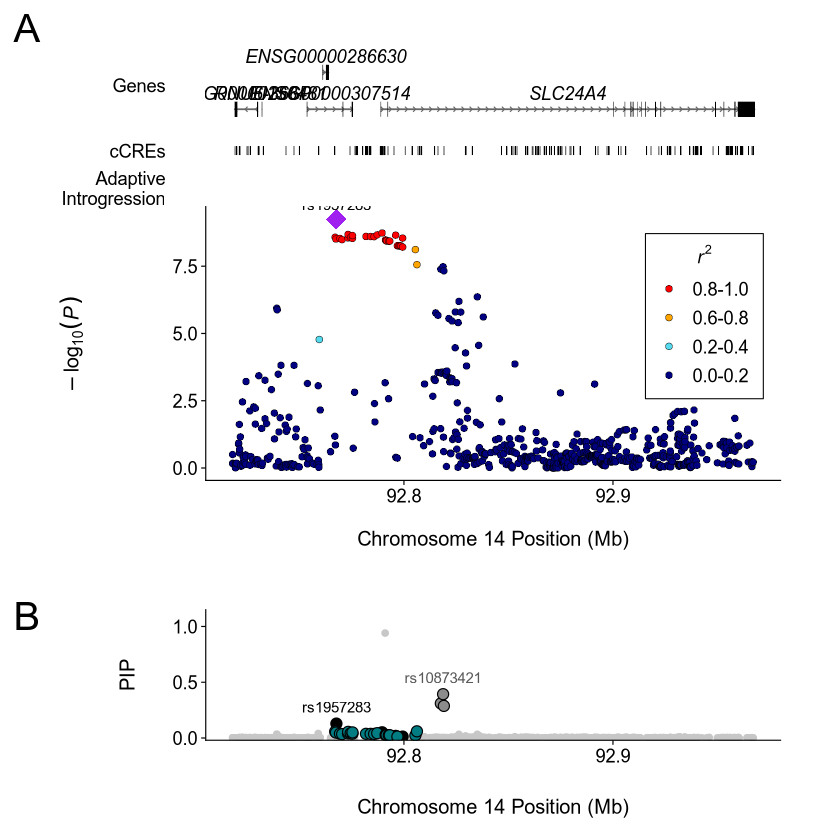

In [45]:
slc24a4_locus <- "14_92773295"

slc24a4_locuszoom_plot <- locuszoom_for_credible_set(
  cancer = scc_gwas,
  ancestry_group = "EUR",
  locus_id = slc24a4_locus,
  credible_set = "L1",
  upstream_kb = 50,
  downstream_kb = 200
)

slc24a4_pips_plot <- plot_credible_set_pips(
  result_file = fine_mapping_result_file(scc_gwas, slc24a4_locus, "EUR"),
  highlight_cs = "L1",
  upstream_kb = 50,
  downstream_kb = 200
)

slc24a4_fine_mapping_example_plot <- stack_locuszoom_and_pips(
  slc24a4_locuszoom_plot, slc24a4_pips_plot
)

slc24a4_fine_mapping_example_plot

In [46]:
save_pdf(
  slc24a4_fine_mapping_example_plot,
  file.path(
    supplementary_figures_directory, "slc24a4_fine_mapping_example.pdf"
  ),
  width = 12,
  height = 8
)

pdf 
  2

#### eQTLs

rs79342051, the highest-PIP variant with a Neanderthal allele called by the
maps, and *SLC24A4* expression: per-sample expression in skeletal muscle (A)
and the effect across GTEx tissues (B), both oriented to the Neanderthal
allele T. Output: `suppl_figs/slc24a4_eqtls.pdf`.

In [47]:
slc24a4_eqtl_variant <- "rs79342051"

# rs12435365, whose Neanderthal allele (G) is inferred as the derived allele,
# should agree in direction and size if it tags the same haplotype
focus_gene_eqtls %>%
  filter(
    locus == "SLC24A4",
    gene_symbol == "SLC24A4",
    tissue == "Muscle_Skeletal"
  ) %>%
  select(rsID, allele, nes, se, p_value, significant)

rsID,allele,nes,se,p_value,significant
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<lgl>
rs79342051,T,0.3643347,0.05325584,0.00000000001637387,TRUE
rs12435365,G,0.3800244,0.05595826,0.00000000002271823,TRUE


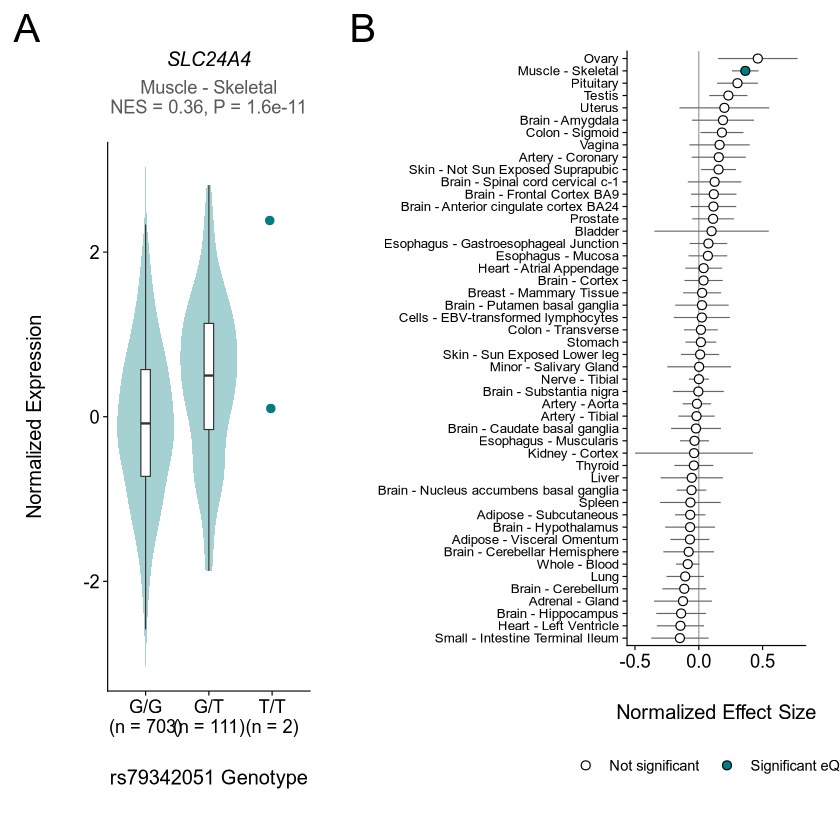

In [48]:
slc24a4_muscle_eqtl_plot <- plot_expression_by_genotype(
  slc24a4_eqtl_variant, "SLC24A4", "Muscle_Skeletal"
)

slc24a4_tissue_effects_plot <- plot_tissue_effects(
  filter(
    focus_gene_eqtls,
    rsID == slc24a4_eqtl_variant,
    gene_symbol == "SLC24A4"
  )
)

slc24a4_eqtls_plot <- plot_grid_labelled(
  slc24a4_muscle_eqtl_plot,
  slc24a4_tissue_effects_plot,
  labels = c("A", "B"),
  nrow = 1,
  rel_widths = c(0.4, 0.6),
  scale = 0.9
)

slc24a4_eqtls_plot

In [49]:
save_pdf(
  slc24a4_eqtls_plot,
  file.path(supplementary_figures_directory, "slc24a4_eqtls.pdf"),
  width = 12,
  height = 9
)

pdf 
  2

### 9.5 *PTHLH*

Outputs: `main_fig_components/pthlh_unconditioned_fine_mapping.pdf`,
`suppl_figs/pthlh_conditioned_locuszoom.pdf` and
`main_fig_components/pthlh_raas.pdf`,
`suppl_figs/pthlh_significant_eqtls.pdf` and
`suppl_figs/pthlh_focus_gene_eqtls.pdf`. The credible set table comes from
`pthlh_credible_set_summary.txt`, written by `analysis.ipynb`; the lead
variant is the highest-PIP variant in each set.

In [50]:
pthlh_summary <- read_tsv(
  file.path(supplementary_tables_directory, "pthlh_credible_set_summary.txt"),
  show_col_types = FALSE
) %>%
  transmute(
    `Ancestry group` = recode(
      ancestry_group, EAS = "East Asian", EUR = "European"
    ),
    CS = str_replace(CS, "^L", "CS"),
    `Lead variant` = lead_variant,
    `Position (Mb)` = sprintf("%.3f", position_mb),
    `Variants (Neanderthal)` = sprintf(
      "%d (%d)", as.integer(n_variants), as.integer(n_neanderthal)
    ),
    `P(Neanderthal)` = sprintf("%.3f", p_neanderthal),
    `Neanderthal β` = if_else(
      is.na(neanderthal_beta), "—", sprintf("%.3f", neanderthal_beta)
    ),
    `max |Z|` = sprintf("%.2f", max_abs_z)
  )

pthlh_summary

Ancestry group,CS,Lead variant,Position (Mb),Variants (Neanderthal),P(Neanderthal),Neanderthal β,max |Z|
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
East Asian,CS1,rs1267211,28.141,34 (27),0.633,-0.134,7.91
European,CS1,rs7297051,28.175,1 (0),0.000,—,17.34
European,CS2,rs10843134,28.359,9 (5),0.541,-0.057,8.85
European,CS3,rs788464,28.153,28 (22),0.789,-0.150,15.52


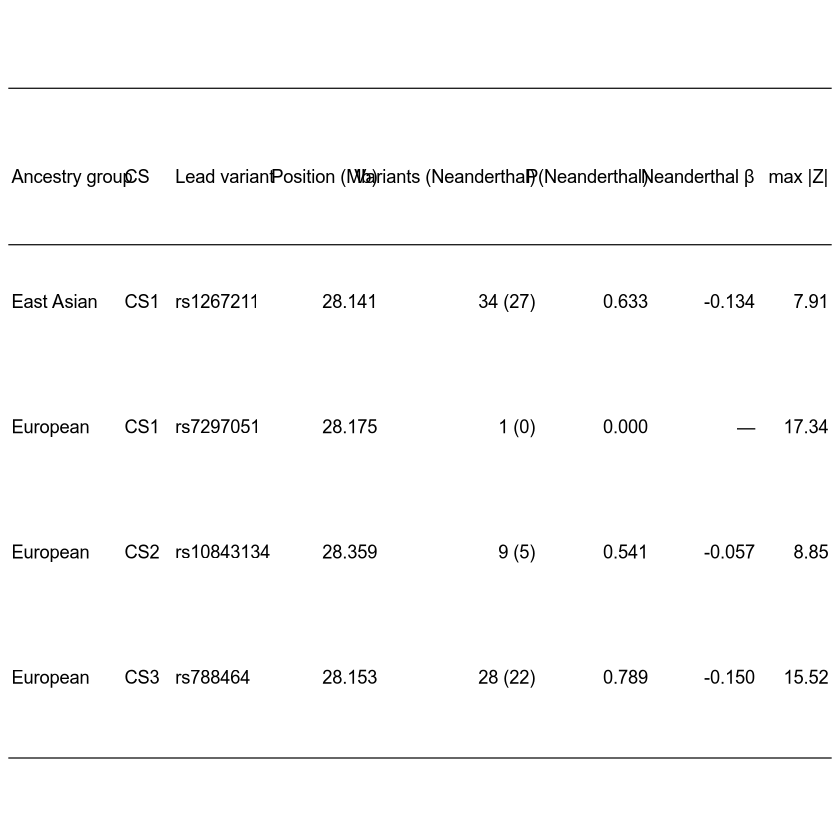

In [51]:
table_panel <- function(df, col_align, text_size = 11, gutter = 6,
                        pad = 0.004) {
  n_col <- ncol(df)
  n_row <- nrow(df)

  widths <- vapply(
    seq_len(n_col),
    function(j) max(nchar(c(names(df)[j], as.character(df[[j]])))),
    numeric(1)
  ) + gutter

  right <- cumsum(widths) / sum(widths)
  left <- c(0, head(right, -1))

  x_pos <- if_else(col_align == 0, left + pad, right - pad)

  cells <- expand_grid(row = seq_len(n_row), col = seq_len(n_col)) %>%
    mutate(
      label = as.character(t(as.matrix(df))[cbind(col, row)]),
      x = x_pos[col],
      hjust = col_align[col],
      y = n_row - row + 1
    )

  header <- tibble(
    label = names(df),
    x = x_pos,
    hjust = col_align,
    y = n_row + 1
  )

  rules <- tibble(y = c(n_row + 1.7, n_row + 0.45, 0.35))

  ggplot() +
    geom_segment(
      data = rules,
      aes(x = 0, xend = 1, y = y, yend = y),
      linewidth = hairline,
      colour = "black"
    ) +
    geom_text(
      data = header,
      aes(x = x, y = y, label = label, hjust = hjust),
      family = "Arial",
      size = text_size / .pt,
      vjust = 0.5
    ) +
    geom_text(
      data = cells,
      aes(x = x, y = y, label = label, hjust = hjust),
      family = "Arial",
      size = text_size / .pt,
      vjust = 0.5
    ) +
    scale_x_continuous(expand = expansion(0)) +
    coord_cartesian(
      xlim = c(0, 1),
      ylim = c(0, n_row + 2.1),
      clip = "off"
    ) +
    theme_void() +
    theme(plot.margin = margin(t = 0, r = 5, b = 0, l = 5))
}

pthlh_summary_table <- table_panel(
  pthlh_summary,
  col_align = c(0, 0, 0, 1, 1, 1, 1, 1)
)

pthlh_summary_table

breast_cancer_EAS_Jia_GCST90429846 | EAS | 12_28143787 | L1

  index variant: rs1267211 (chr12:28,140,829, PIP 0.107)

  credible set:  34 variants, 27 introgressed, spanning 30 kb

  sumstats:      breast_cancer_EAS_Jia_GCST90429846_hg19.txt.gz

  columns:       chromosome / base_pair_location / p_value / rsid

Warning message in resolve_locus_inputs(cancer, ancestry_group, locus_id, credible_set, :
“breast_cancer_EAS_Jia_GCST90429846 positions are hg38, not hg19; the gene track, cCREs and introgression regions are hg19.”
Warning message in `[.data.table`(gff, , `:=`(gene_name, str_extract(attr, "(?<=gene_name=)[^;]+"))):
“A shallow copy of this data.table was taken so that := can add or remove 1 columns by reference. At an earlier point, this data.table was copied by R (or was created manually using structure() or similar). Avoid names<- and attr<- which in R currently (and oddly) may copy the whole data.table. Use set* syntax instead to avoid copying: ?set, ?setnames and ?setattr. I

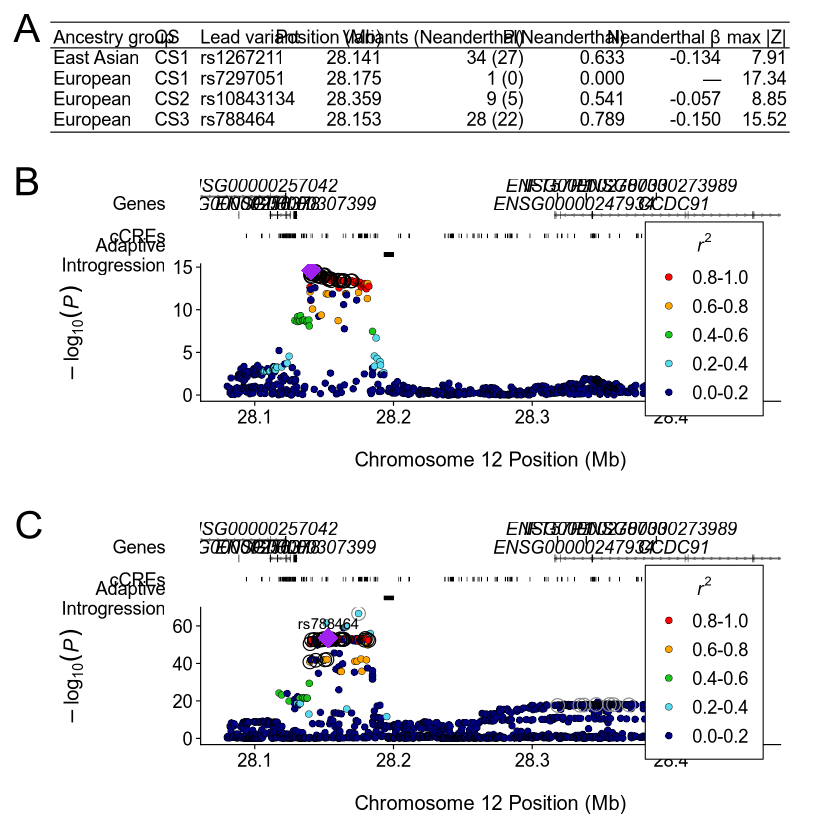

In [52]:
breast_eas_gwas <- "breast_cancer_EAS_Jia_GCST90429846"
breast_eur_gwas <- "breast_cancer_EUR_Zhang_GCST001"
pthlh_eas_locus <- "12_28143787"
pthlh_eur_locus <- "12_28153018"
pthlh_window <- c(28080000, 28460000)

pthlh_eas_unconditioned_locuszoom_plot <- locuszoom_for_credible_set(
  cancer = breast_eas_gwas,
  ancestry_group = "EAS",
  locus_id = pthlh_eas_locus,
  credible_set = "L1",
  mark_credible_sets = TRUE,
  start_bp_override = pthlh_window[1],
  end_bp_override = pthlh_window[2],
  gwas_path = file.path(
    gwas_summary_stats_directory, paste0(breast_eas_gwas, "_hg19.txt.gz")
  )
)

pthlh_eur_unconditioned_locuszoom_plot <- locuszoom_for_credible_set(
  cancer = breast_eur_gwas,
  ancestry_group = "EUR",
  locus_id = pthlh_eur_locus,
  credible_set = "L3",
  mark_credible_sets = TRUE,
  start_bp_override = pthlh_window[1],
  end_bp_override = pthlh_window[2]
)

pthlh_fine_mapping_plot <- plot_grid_labelled(
  pthlh_summary_table,
  pthlh_eas_unconditioned_locuszoom_plot,
  pthlh_eur_unconditioned_locuszoom_plot,
  labels = c("A", "B", "C"),
  ncol = 1,
  rel_heights = c(2.5, 5.6, 5.6),
  scale = 0.9
)

pthlh_fine_mapping_plot

In [53]:
save_pdf(
  pthlh_fine_mapping_plot,
  file.path(main_figures_directory, "pthlh_unconditioned_fine_mapping.pdf"),
  width = 12,
  height = 12.7
)

pdf 
  2

Both windows conditioned on rs7297051. These plotting files are PLINK-style
(`CHR`, `BP`, `P`, `SNP`); the conditional Z-scores analysed in
`analysis.ipynb` come from `*_conditioned_on_rs7297051.txt` in the same
directory, and both should reflect the same conditioning run.

breast_cancer_EAS_Jia_GCST90429846 | EAS | 12_28143787 | L1

  index variant: rs1267211 (chr12:28,140,829, PIP 0.107)

  credible set:  34 variants, 27 introgressed, spanning 30 kb

  sumstats:      pthlh_breast_EAS_conditioned.txt.gz

  columns:       CHR / BP / P / SNP

Warning message in `[.data.table`(gff, , `:=`(gene_name, str_extract(attr, "(?<=gene_name=)[^;]+"))):
“A shallow copy of this data.table was taken so that := can add or remove 1 columns by reference. At an earlier point, this data.table was copied by R (or was created manually using structure() or similar). Avoid names<- and attr<- which in R currently (and oddly) may copy the whole data.table. Use set* syntax instead to avoid copying: ?set, ?setnames and ?setattr. It's also not unusual for data.table-agnostic packages to produce tables affected by this issue. If this message doesn't help, please report your use case to the data.table issue tracker so the root cause can be fixed or this message improved.”
breast_cance

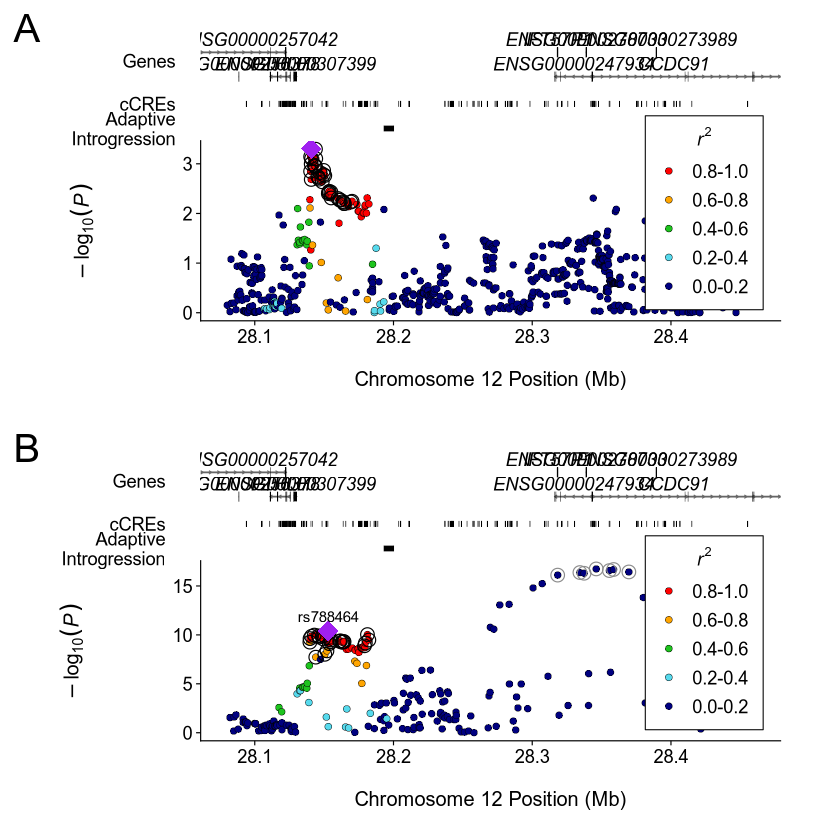

In [54]:
plot_conditioned_locuszoom <- function(gwas, ancestry_group, locus_id,
                                       credible_set) {
  locuszoom_for_credible_set(
    cancer = gwas,
    ancestry_group = ancestry_group,
    locus_id = locus_id,
    credible_set = credible_set,
    mark_credible_sets = TRUE,
    start_bp_override = pthlh_window[1],
    end_bp_override = pthlh_window[2],
    gwas_path = file.path(
      fine_mapping_directory, "conditional",
      paste0("pthlh_breast_", ancestry_group, "_conditioned.txt.gz")
    ),
    chr_col = "CHR",
    pos_col = "BP",
    pval_col = "P",
    rsid_col = "SNP"
  )
}

pthlh_eas_conditioned_locuszoom_plot <- plot_conditioned_locuszoom(
  breast_eas_gwas, "EAS", pthlh_eas_locus, "L1"
)
pthlh_eur_conditioned_locuszoom_plot <- plot_conditioned_locuszoom(
  breast_eur_gwas, "EUR", pthlh_eur_locus, "L3"
)

pthlh_conditioned_locuszoom_plot <- plot_grid_labelled(
  pthlh_eas_conditioned_locuszoom_plot,
  pthlh_eur_conditioned_locuszoom_plot,
  labels = c("A", "B"),
  ncol = 1,
  align = "v",
  axis = "lr",
  rel_heights = c(5.6, 5.6),
  scale = 0.9
)

pthlh_conditioned_locuszoom_plot

In [55]:
save_pdf(
  pthlh_conditioned_locuszoom_plot,
  file.path(
    supplementary_figures_directory, "pthlh_conditioned_locuszoom.pdf"
  ),
  width = 12,
  height = 11.2
)

pdf 
  2

Reintroduced ancestral allele rs788464. Panels A (schematic) and B (credible
set table) are placeholders completed in Inkscape.

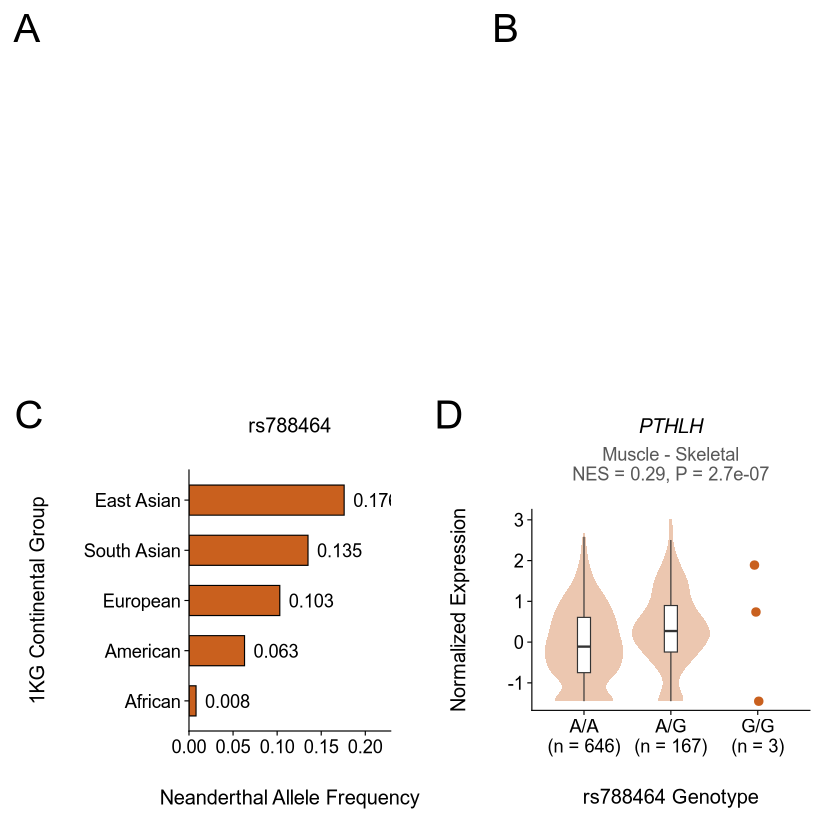

In [56]:
# 1000 Genomes Phase 3 continental-group frequencies of the reintroduced
# ancestral allele
rs788464_afs_plot <- plot_allele_frequencies(
  c(
    African = 0.008,
    American = 0.063,
    `East Asian` = 0.176,
    European = 0.103,
    `South Asian` = 0.135
  ),
  "rs788464",
  fill = raa_colour
)

# Per-sample GTEx expression of PTHLH in skeletal muscle by rs788464 genotype
rs788464_muscle_eqtl_plot <- plot_expression_by_genotype(
  "rs788464",
  "PTHLH",
  "Muscle_Skeletal",
  colour = raa_colour
)

pthlh_raas_plot <- plot_grid(
  plot_grid_labelled(
    NULL, NULL, labels = c("A", "B"), nrow = 1, rel_widths = c(0.57, 0.43)
  ),
  plot_grid_labelled(
    rs788464_afs_plot,
    rs788464_muscle_eqtl_plot,
    labels = c("C", "D"),
    nrow = 1,
    rel_widths = c(0.5, 0.5),
    scale = 0.9
  ),
  ncol = 1,
  rel_heights = c(0.46, 0.54)
)

pthlh_raas_plot

In [57]:
save_pdf(
  pthlh_raas_plot,
  file.path(main_figures_directory, "pthlh_raas.pdf"),
  width = 12,
  height = 8
)

pdf 
  2

#### eQTLs

Two supplementary figures, both oriented to the G allele at rs788464 (CS3,
reintroduced ancestral allele) and rs10843134 (CS2):

- every significant GTEx eQTL for the two variants
  (`suppl_figs/pthlh_significant_eqtls.pdf`);
- the effects of both variants on *PTHLH*, *CCDC91* and ENSG00000247934 in
  every tissue (`suppl_figs/pthlh_focus_gene_eqtls.pdf`).

In [58]:
pthlh_significant_eqtls <- filter(significant_eqtls, locus == "PTHLH")

# Pairs where the credible set variant is not GTEx's lead eQTL need an LD
# check against the lead before they are read as the same signal
pthlh_significant_eqtls %>%
  count(rsID, is_gtex_lead)

rsID,is_gtex_lead,n
<chr>,<lgl>,<int>
rs10843134,FALSE,89
rs788464,FALSE,2


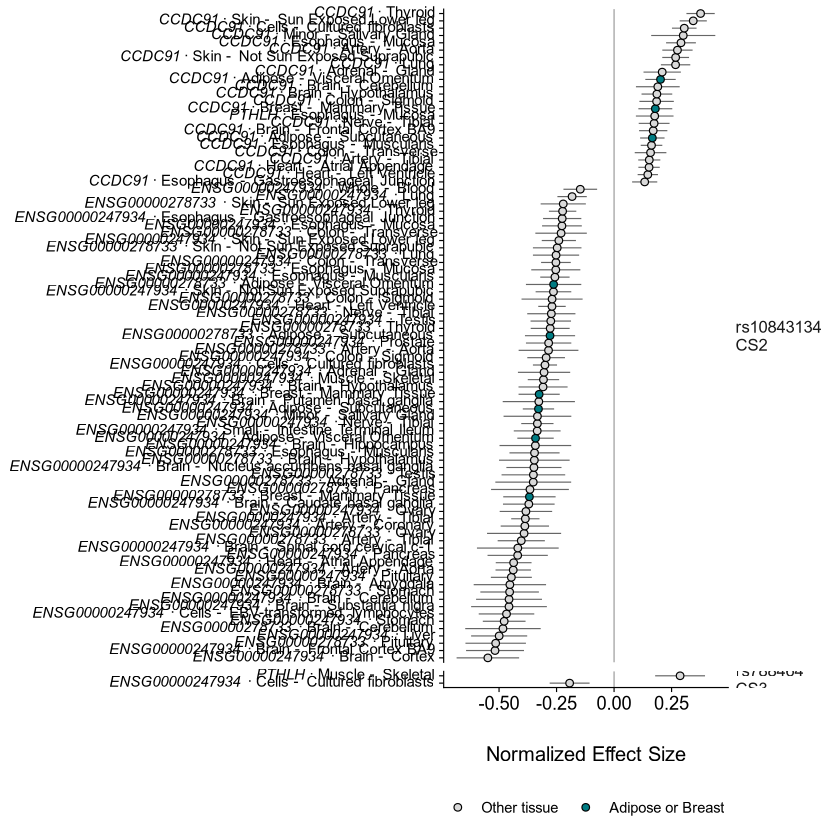

In [59]:
pthlh_significant_eqtls_plot <- plot_significant_eqtls(
  pthlh_significant_eqtls
)

pthlh_significant_eqtls_plot

In [60]:
# One row per significant pair, so the page grows with them
save_pdf(
  pthlh_significant_eqtls_plot,
  file.path(supplementary_figures_directory, "pthlh_significant_eqtls.pdf"),
  width = 9,
  height = max(5, 0.12 * nrow(pthlh_significant_eqtls) + 1.5)
)

pdf 
  2

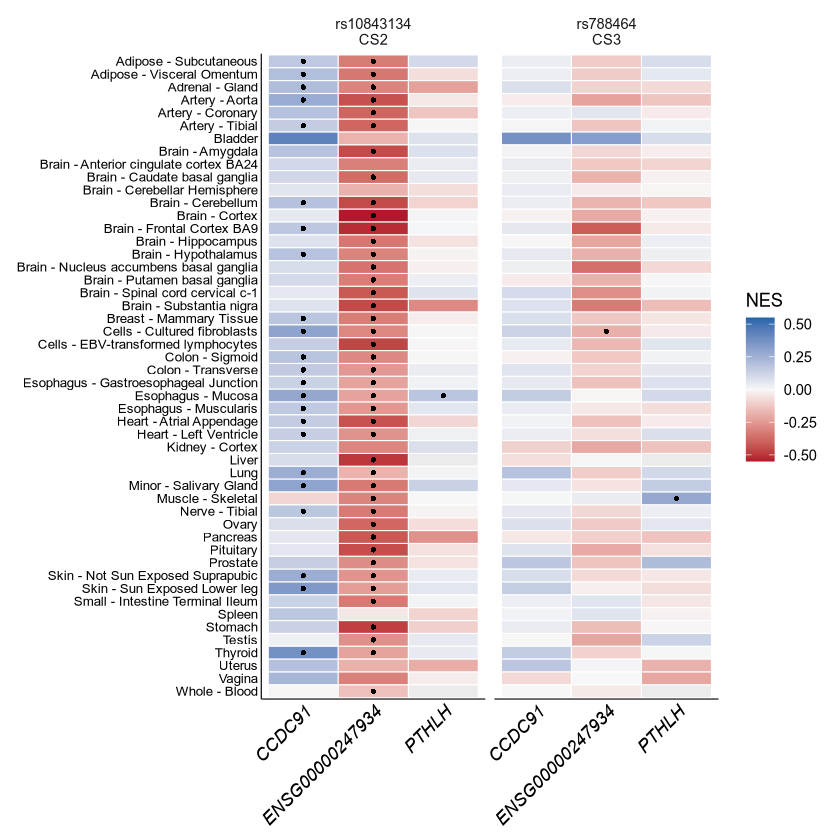

In [61]:
pthlh_focus_gene_eqtls_plot <- plot_focus_gene_heatmap(
  filter(focus_gene_eqtls, locus == "PTHLH")
)

pthlh_focus_gene_eqtls_plot

In [62]:
save_pdf(
  pthlh_focus_gene_eqtls_plot,
  file.path(supplementary_figures_directory, "pthlh_focus_gene_eqtls.pdf"),
  width = 7,
  height = 10
)

pdf 
  2

## 10. Ancient DNA

rs2026804 allele frequency through time, from the binned frequencies written
by `analysis.ipynb` (Section 10 there describes the binning, deduplication
and Wilson intervals). Output: `suppl_figs/rs2026804_binned_DAFs.pdf`.

In [63]:
rs2026804_binned_dafs <- read_tsv(
  file.path(ancient_genomes_directory, "rs2026804_binned_DAFs.txt"),
  show_col_types = FALSE
) %>%
  # bin_order restores the display order: oldest bin first, present-day last
  mutate(
    date_bin = factor(date_bin, levels = unique(date_bin[order(bin_order)]))
  )

rs2026804_binned_dafs

date_bin,Region,sample_size,total_alleles,derived_alleles,allele_frequency,ci_low,ci_high,bin_order
<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
[50-20),East Asia,3,4,0,0.00000000,0.00000000000000000000000,0.48989084,0
[50-20),Europe,8,8,0,0.00000000,0.00000000000000000000000,0.32440756,0
[20-10),Africa,2,2,0,0.00000000,0.00000000000000000000000,0.65761977,1
[20-10),Americas,6,6,0,0.00000000,0.00000000000000000000000,0.39033429,1
[20-10),Europe,9,9,6,0.66666667,0.35420213558039631562835,0.87941618,1
[20-10),West Asia,2,2,2,1.00000000,0.34238022750665320081964,1.00000000,1
[10-5),Africa,3,4,0,0.00000000,0.00000000000000000000000,0.48989084,2
[10-5),Americas,8,8,0,0.00000000,0.00000000000000000000000,0.32440756,2
[10-5),East Asia,36,36,1,0.02777778,0.00492040713981044958159,0.14169719,2


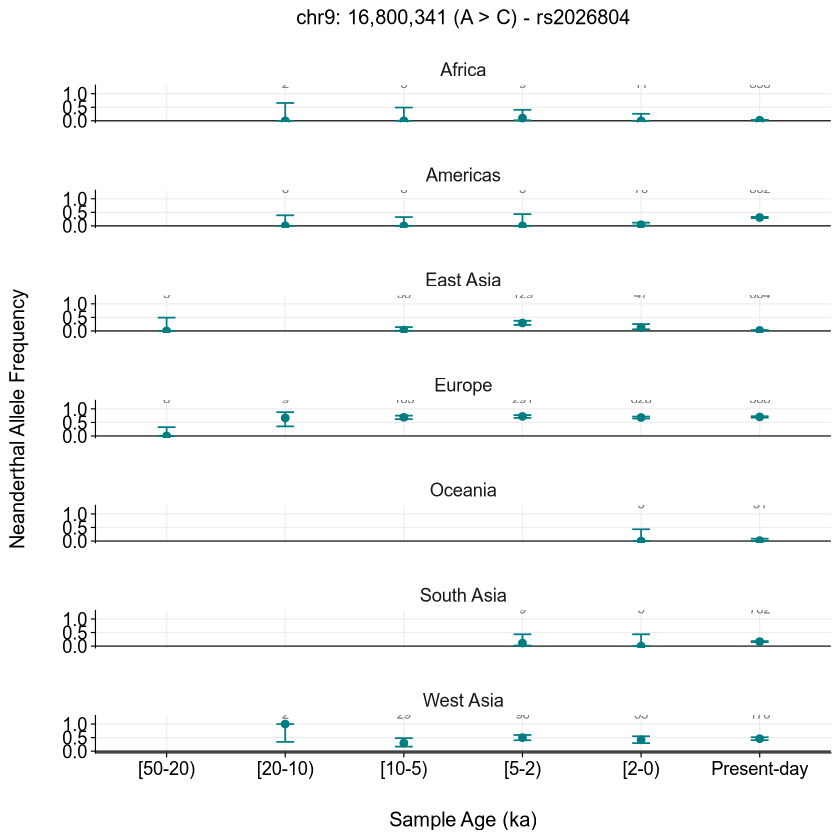

In [64]:
rs2026804_binned_dafs_plot <- ggplot(
  rs2026804_binned_dafs,
  aes(x = date_bin, y = allele_frequency)
) +
  geom_hline(yintercept = 0, colour = "black", linewidth = hairline) +
  geom_errorbar(
    aes(ymin = ci_low, ymax = ci_high),
    width = 0.15,
    colour = primary_colour
  ) +
  geom_point(size = 1.8, colour = primary_colour) +
  geom_text(
    aes(y = 1.0, label = sample_size),
    colour = "grey45",
    family = "Arial",
    size = 8 / .pt,
    vjust = -0.6
  ) +
  scale_y_continuous(breaks = c(0, 0.5, 1)) +
  # drop = FALSE keeps empty bins in place so the panels stay aligned across
  # regions
  scale_x_discrete(drop = FALSE) +
  coord_cartesian(ylim = c(0, 1.25)) +
  facet_wrap(~ Region, ncol = 1) +
  labs(
    x = "Sample Age (ka)",
    y = "Neanderthal Allele Frequency",
    title = "chr9: 16,800,341 (A > C) - rs2026804"
  ) +
  fig_theme +
  theme(
    axis.line.x = element_blank(),
    legend.position = "none",
    panel.grid.major = element_line(colour = "grey93", linewidth = hairline),
    panel.spacing = unit(1.5, "lines"),
    plot.title = element_text(
      hjust = 0.5,
      size = 12,
      margin = margin(t = 0, b = 15)
    ),
    strip.background = element_blank(),
    strip.text = element_text(hjust = 0.5, size = 11)
  )

rs2026804_binned_dafs_plot

In [65]:
save_pdf(
  rs2026804_binned_dafs_plot,
  file.path(supplementary_figures_directory, "rs2026804_binned_DAFs.pdf"),
  width = 10,
  height = 12
)

pdf 
  2

## 11. Heritability

Heritability enrichment in Neanderthal variants for the GWAS that pass QC.
Which GWAS pass, and why the others do not, comes from `heritability_qc.txt`
written by `analysis.ipynb` (mean χ² ≥ 1.02 and observed h² ≥ 0.05), so the
figure and Tables S11 and S12 cannot disagree. Output:
`main_fig_components/h2_enrichments.pdf`.

Panel C uses heritability enrichment estimates from GENIE run on UK Biobank
individual-level genotypes (application 226956). UK Biobank's access terms do
not permit redistribution of individual-level data, so those analyses were run
within the approved environment and are not reproduced here; the summary
estimates are entered directly below. Researchers with approved UK Biobank
access can obtain the analysis code from the authors on request.

In [66]:
heritability_qc <- read_tsv(
  file.path(supplementary_tables_directory, "heritability_qc.txt"),
  show_col_types = FALSE
) %>%
  # pandas writes True/False; make sure the column is logical either way
  mutate(included = as.logical(toupper(as.character(included))))

heritability_qc %>%
  filter(!included) %>%
  select(study, reason_not_included, mean_chi2, h2_observed)

study,reason_not_included,mean_chi2,h2_observed
<chr>,<chr>,<dbl>,<dbl>
bladder_cancer_EUR_Rashkin_GCST90011817,Heritability below 0.05,1.0282,0.0035
endometrial_cancer_EAS_Sakaue_GCST90018618,Mean chi-square below 1.02,1.0102,0.0129
endometrial_cancer_EUR_OMara_GCST006464,Heritability below 0.05,1.1255,0.0371
esophageal_cancer_EAS_Sakaue_GCST90018621,Heritability below 0.05,1.0338,0.0199
esophageal_cancer_EUR_Rashkin_GCST90011807,Mean chi-square below 1.02,1.0107,0.0009
gastric_cancer_EAS_Sakaue_GCST90018629,Heritability below 0.05,1.0386,0.0161
gastric_cancer_EUR_Zhou_GCST90435577,Mean chi-square below 1.02,0.9993,0.0002
liver_cancer_EAS_Sakaue_GCST90018583,Mean chi-square below 1.02,0.9948,-0.0067
liver_cancer_EUR_Zhou_GCST90435580,Mean chi-square below 1.02,1.0046,0.0006


In [67]:
neanderthal_map_studies <- c(
  "Browning_et_al_2018", "Sankararaman_et_al_2016",
  "Skov_2024", "Vernot_et_al_2016"
)
map_suffix <- paste0("_(", paste(neanderthal_map_studies, collapse = "|"), ")$")

h2_enrichments <- read_tsv(
  file.path(ldsc_directory, "introgressed_variants_heritability_summary.txt"),
  show_col_types = FALSE
)

# Older summaries append the map to `gwas` instead of a variant_set column
if (!"variant_set" %in% names(h2_enrichments)) {
  h2_enrichments$variant_set <- str_match(h2_enrichments$gwas, map_suffix)[, 2]
}

included_studies <- heritability_qc %>%
  filter(included) %>%
  pull(study)

filtered_h2_enrichments <- h2_enrichments %>%
  mutate(
    study = str_remove(gwas, map_suffix),
    cancer = short_cancer(study),
    ancestry_group = str_extract(study, "(?<=_)(EUR|EAS)(?=_)")
  ) %>%
  filter(study %in% included_studies) %>%
  select(cancer, ancestry_group, variant_set, everything(), -gwas, -study)

count(filtered_h2_enrichments, ancestry_group, cancer)

ancestry_group,cancer,n
<chr>,<chr>,<int>
EAS,Breast,4
EAS,Prostate,4
EUR,BCC,4
EUR,Breast,4
EUR,Colorectal,4
EUR,Lung,4
EUR,Prostate,4
EUR,SCC,4


In [68]:
n_eas_cancers_h2 <- filtered_h2_enrichments %>%
  filter(ancestry_group == "EAS") %>%
  distinct(cancer) %>%
  nrow()

n_eur_cancers_h2 <- filtered_h2_enrichments %>%
  filter(ancestry_group == "EUR") %>%
  distinct(cancer) %>%
  nrow()

# The x axis, title and margins in units of one cancer row; larger than in
# Section 5 because these panels carry a title as well as an axis
h2_axis_overhead <- 2.5

# Height of the GENIE panel in the same units
genie_height <- 4

In [69]:
plot_cancer_h2_enrichments <- function(filtered_h2_enrichments,
                                       target_ancestry_group,
                                       ancestry_group_title) {
  enrichment_min <- 0.25
  enrichment_mid <- 1
  enrichment_max <- 4

  # Diverging ramp anchored on 1, where white means no enrichment
  enrichment_colours <- c(
    "#67001F", "#D6604D", "#FDDBC7", "#F7F7F7", "#D1E5F0", "#4393C3", "#053061"
  )
  enrichment_breaks <- rescale(
    c(enrichment_min, 0.75, 0.9, enrichment_mid, 1.2, 2, enrichment_max)
  )

  enrichments <- filtered_h2_enrichments %>%
    filter(ancestry_group == target_ancestry_group) %>%
    mutate(Enrichment = pmax(Enrichment, enrichment_min))

  ggplot(enrichments, aes(y = reorder(cancer, Enrichment), x = Enrichment)) +
    geom_vline(
      xintercept = 1,
      linetype = "dotted",
      colour = "black",
      linewidth = hairline
    ) +
    geom_point(
      aes(fill = Enrichment),
      shape = 21,
      size = 5,
      colour = "black",
      show.legend = FALSE
    ) +
    scale_x_continuous(
      trans = "log10",
      breaks = c(0.25, 0.5, 1, 2, 4, 8),
      limits = c(enrichment_min, enrichment_max)
    ) +
    scale_fill_gradientn(
      colours = enrichment_colours,
      values = enrichment_breaks,
      limits = c(enrichment_min, enrichment_max),
      name = "Enrichment"
    ) +
    labs(
      x = "Heritability Enrichment in Neanderthal Variants",
      y = "Cancer",
      title = paste(ancestry_group_title, "GWAS")
    ) +
    fig_theme +
    theme(
      plot.title = element_text(
        hjust = 0.5,
        size = 12,
        margin = margin(b = 20)
      )
    )
}

eas_h2_enrichments_plot <- plot_cancer_h2_enrichments(
  filtered_h2_enrichments, "EAS", "East Asian"
)

eur_h2_enrichments_plot <- plot_cancer_h2_enrichments(
  filtered_h2_enrichments, "EUR", "European"
)

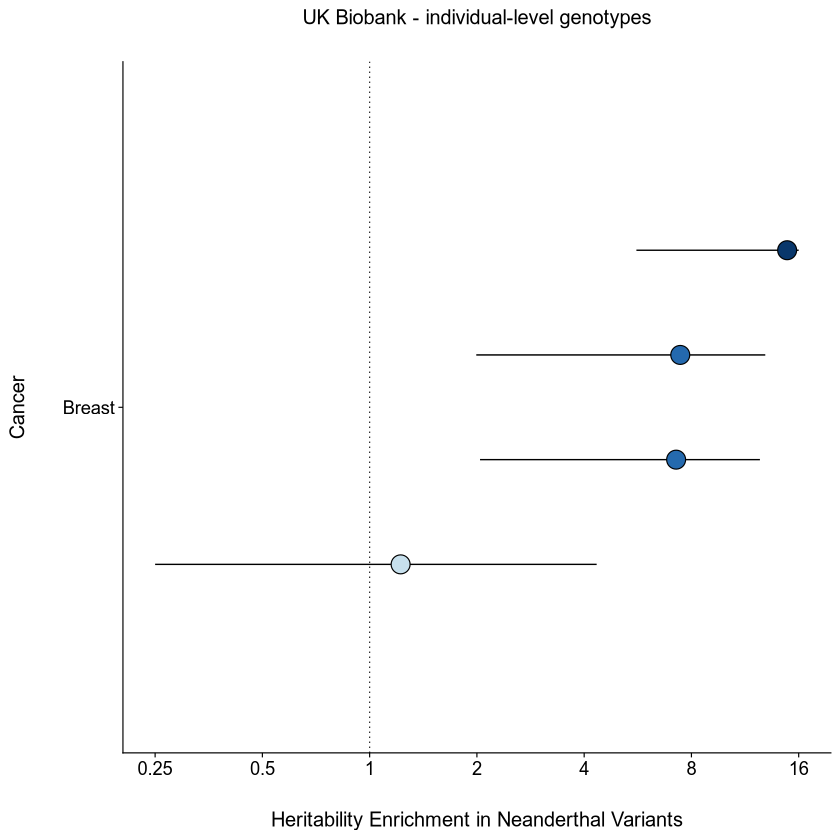

In [70]:
# GENIE enrichment estimates for breast cancer from UK Biobank
# individual-level genotypes, typed in from the GENIE output
genie_enrichments <- tibble(
  cancer = "Breast",
  variant_set = c(
    "Browning et al. 2018", "Sankararaman et al. 2016",
    "Skov 2024", "Vernot et al. 2016"
  ),
  n_snps = c(4933, 14120, 5844, 2965),
  Enrichment = c(7.24726, 1.22167, 7.44254, 14.8498),
  SE = c(5.20652, 3.11481, 5.45068, 9.24386)
) %>%
  # Spread the four estimates vertically around the single "Breast" row,
  # lowest enrichment at the bottom
  mutate(
    y = seq(0.85, 1.15, length.out = n())[
      rank(Enrichment, ties.method = "first")
    ]
  )

plot_genie_h2_enrichments <- function(
    genie_enrichments,
    plot_title = "UK Biobank - individual-level genotypes") {
  enrichment_min <- 0.25
  enrichment_mid <- 1
  enrichment_max <- 16

  enrichment_colours <- c(
    "#67001F", "#D6604D", "#F4A582", "#FDDBC7",
    "#F7F7F7",
    "#D1E5F0", "#92C5DE", "#4393C3", "#2166AC", "#053061"
  )
  enrichment_breaks <- rescale(
    c(enrichment_min, 0.75, 0.9, enrichment_mid, 1.5, 4, enrichment_max)
  )

  ggplot(genie_enrichments, aes(y = y, x = Enrichment)) +
    geom_errorbar(
      aes(
        xmin = pmax(Enrichment - SE, enrichment_min),
        xmax = pmin(Enrichment + SE, enrichment_max)
      ),
      width = 0,
      linewidth = 0.4,
      orientation = "y"
    ) +
    geom_point(
      aes(fill = Enrichment),
      shape = 21,
      size = 5,
      colour = "black",
      show.legend = FALSE
    ) +
    geom_vline(
      xintercept = 1,
      linetype = "dotted",
      colour = "black",
      linewidth = hairline
    ) +
    scale_x_continuous(
      trans = "log10",
      breaks = c(0.25, 0.5, 1, 2, 4, 8, 16),
      labels = c(0.25, 0.5, 1, 2, 4, 8, 16),
      limits = c(enrichment_min, enrichment_max)
    ) +
    scale_y_continuous(breaks = 1, labels = "Breast", limits = c(0.7, 1.3)) +
    scale_fill_gradientn(
      colours = enrichment_colours,
      values = enrichment_breaks,
      limits = c(enrichment_min, enrichment_max),
      name = "Enrichment"
    ) +
    labs(
      x = "Heritability Enrichment in Neanderthal Variants",
      y = "Cancer",
      title = plot_title
    ) +
    fig_theme +
    theme(
      plot.title = element_text(
        hjust = 0.5,
        size = 12,
        margin = margin(b = 20)
      )
    )
}

genie_h2_enrichments_plot <- plot_genie_h2_enrichments(genie_enrichments)
genie_h2_enrichments_plot

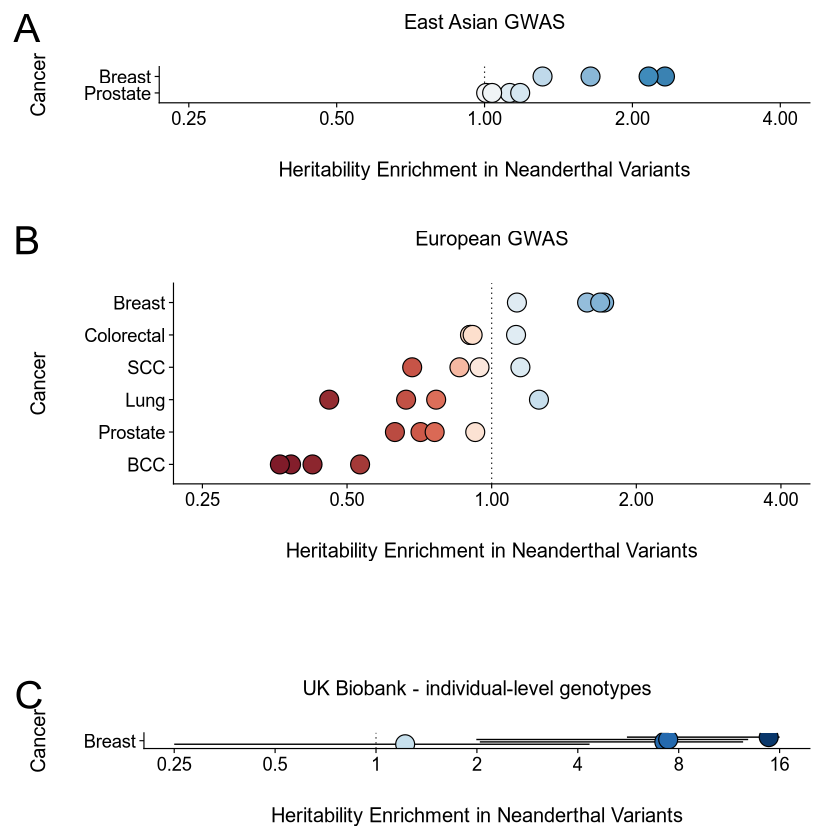

In [71]:
h2_panel <- function(plot, label) {
  plot_grid_labelled(plot, labels = label, ncol = 1, scale = 0.95)
}

# Space between B and C for the depletion-to-enrichment colour arrow, which
# is added in Inkscape
colour_arrow_gap <- 2

h2_enrichments_plot <- plot_grid(
  h2_panel(eas_h2_enrichments_plot, "A"),
  NULL,
  h2_panel(eur_h2_enrichments_plot, "B"),
  NULL,
  h2_panel(genie_h2_enrichments_plot, "C"),
  ncol = 1,
  rel_heights = c(
    n_eas_cancers_h2 + h2_axis_overhead,
    0.4,
    n_eur_cancers_h2 + h2_axis_overhead,
    colour_arrow_gap,
    genie_height
  )
)

h2_enrichments_plot

In [72]:
save_pdf(
  h2_enrichments_plot,
  file.path(main_figures_directory, "h2_enrichments.pdf"),
  width = 10,
  height = 12
)

pdf 
  2

## 13. Session information

In [73]:
sessionInfo()

R version 4.5.3 (2026-03-11)
Platform: x86_64-conda-linux-gnu
Running under: Rocky Linux 8.10 (Green Obsidian)

Matrix products: default
BLAS/LAPACK: /wynton/home/capra/cbrand/miniconda3/envs/rgenomics/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] yaml_2.3.12        tidyr_1.3.2        stringr_1.6.0      scales_1.4.0      
 [5] readr_2.2.0        patchwork_1.3.2    gtable_0.3.6       gridExtra_2.3.1   
 [9] ggtext_0.1.2   